# Final project: AI, economic perceptions and consumer sentiment before the 2026 midterms

This notebook reproduces every table and figure in `REPORT.pdf`.
- It does not download data or call any AI model itself. The collectors (`scripts/01` to `03`), the corpus build (`05`), the samples (`06`) and the AI labelling (documented in the README) write their results to `data/`.
- The first code cell re-runs the economic baseline (`04`), the validation (`08`), the media measures (`09`), the Tier C checks (`09c`), the analysis (`10`), the exploratory Reddit question (`10b`) and the figures (`11`) on the saved data, so everything below is computed here, the same way as for the report.
- Each section starts with the report's own text (copied from `REPORT.md`), then shows the tables behind it, then a short "How this is computed" note where useful.

In [1]:
import sys, json, warnings, subprocess
sys.path.insert(0, '.'); sys.path.insert(0, 'scripts')
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 80)
from src.config import TABLES, FIGURES, OUTPUTS, PREREG, PREREG_NOTES
# recompute every result from the saved data and codes, exactly as for the report. Steps that need the
# collected text (not redistributed: headline and post text) are skipped when it is absent, and the committed
# outputs of those steps are used instead.
from pathlib import Path
needs = {'scripts/04_econ_baseline.py': [], 'scripts/08_validation.py': ['data/labels/gold_sheet.csv', 'data/coded/codes.parquet'],
         'scripts/09_media_measures.py': ['data/interim/news.parquet', 'data/coded/codes.parquet'],
         'scripts/09b_tierc_realtime.py': ['data/interim/news.parquet', 'data/coded/codes.parquet'],
         'scripts/09c_tierc_checks.py': ['data/interim/news.parquet', 'data/coded/codes.parquet'],
         'scripts/10_analysis.py': [],
         'scripts/10b_reddit_exploratory.py': ['data/interim/reddit.parquet', 'data/labels/gold_sheet.csv'],
         'scripts/11_make_figures.py': []}
for s, req in needs.items():
    missing = [f for f in req if not Path(f).exists()]
    if missing:
        print(s, 'skipped (needs', ', '.join(missing), '); using the committed outputs')
        continue
    r = subprocess.run([sys.executable, s], capture_output=True, text=True)
    print(s, 'exit', r.returncode)
    assert r.returncode == 0, r.stderr[-3000:]
E = json.loads((OUTPUTS / 'results_econ.json').read_text())
V = json.loads((OUTPUTS / 'results_validation.json').read_text())
MED = json.loads((OUTPUTS / 'results_media.json').read_text())
R = json.loads((OUTPUTS / 'results.json').read_text())
TC = json.loads((OUTPUTS / 'results_tierc.json').read_text())
RD = json.loads((OUTPUTS / 'results_reddit.json').read_text())

scripts/04_econ_baseline.py exit 0


scripts/08_validation.py exit 0


scripts/09_media_measures.py exit 0


scripts/09b_tierc_realtime.py exit 0


scripts/09c_tierc_checks.py exit 0


scripts/10_analysis.py exit 0


scripts/10b_reddit_exploratory.py exit 0


scripts/11_make_figures.py exit 0


# Final Project report

### AI, economic perceptions and consumer sentiment before the 2026 midterms: Jan 2010 to Oct 12, 2026

FRE-GY 7871 A · NLP and the Investment Process

**Name:** Aditya Gupta

**NetID:** ag11023

**GitHub repo:** https://github.com/Aditya-Gupta26/FRE_GY_7871_Final_Project

---

## 1. What I did

**The question.**
- Michigan consumer sentiment (ICS, index points, 1966 = 100) averaged 51.2 over Jan to Oct 2026 and hit a record low of 44.8 in May, while unemployment was only 4.1% to 4.4% and real GDP kept growing.
- The brief asks where this gap comes from: (H1) household pressures the headline numbers miss, (H2) perceptions shaped by coverage, framing or biases, or (H3) measurement, timing or an incomplete model.
- I treated all three as hypotheses and wrote down the rules for judging them before running any test (the pre-registration).

**What I built.**
- **Economy in real time:** unemployment, headline PCE inflation and GDP growth, each as published by day 14 of the survey month.
- **Media corpus:** 602,189 headlines from 34 outlets (Dec 2009 to Oct 12, 2026) and 50,926 Reddit posts.
- **AI measurement:** Claude Opus labelled 9,373 items on the brief's five dimensions, checked against 450 gold items, a word list and a simple classifier.
- **Tier C:** the Claude usage limit capped Opus at about 9,400 items, but monthly tests need all 125,440 economic headlines from the outlet pulls scored. So a simple classifier (TF-IDF + logistic regression) learned from Opus's labels and scored them all (Section 3). "Tier C" because Tiers A and B are the samples Opus labelled itself.

**Annotation disclosure.** The brief asks for two independent *human* annotators. I couldn't find other people, so the two passes are Claude Sonnet 5.5 and Claude Haiku 5.5, each labelling the 450 gold items in its own context, plus my corrections to both; Claude Fable 5.1 settled the items where they still disagreed. None of these is the Opus coder. Because I corrected both passes, I report the two models' agreement before my corrections.

**How to read the numbers.**
- **Index points:** the unit of ICS and its parts, ICC (current conditions) and ICE (expectations). **Gap:** actual ICS minus Model E's prediction for the same month, in index points; negative = gloomier than the economy predicts. "% of the gap" means a share of the 2026 average gap of -39.9 points, unless another model's gap is named.
- **Net negativity:** share of relevant headlines that are negative minus the share positive (-1 to +1). **RMSE:** typical forecast miss, in index points. **R²:** share of one series' ups and downs another explains (0 to 1).
- **p:** chance of a result this strong if nothing were going on (0.05 is the usual bar); **q:** the same, corrected for several tests. **κ, macro-F1:** labeller agreement beyond chance and a tool's accuracy averaged over classes (0 to 1, 1 = perfect).
- **Exploratory:** not in the written pre-registration, or added after the main results: a lead, not a test. **Tests:** EWC standard errors (honest when monthly errors are correlated); Toda-Yamamoto (which series moves first); Clark-West, DM-HLN (does one forecast beat another); Shapley (splits a joint effect between two groups of variables).

**Table 1. Events in the monitoring window (2026; sources in References).**

| Date | Event |
|---|---|
| Jan 31 to Feb 3 | Partial shutdown (Jan jobs report delayed to Feb 11) |
| Feb 20 | Supreme Court: IEEPA does not authorise tariffs; 10% Section 122 surcharge from Feb 24 |
| Feb 28 | US-Iran conflict begins; gasoline $2.94 (Feb 23) to $3.50 (Mar 9), peak $4.50 (May 11) |
| Mar 6 | Feb jobs report: -92k payrolls, unemployment 4.4% |
| May 22 | Michigan May final 44.8, a record low; Warsh sworn in as Fed chair |
| Jun 10 | May CPI 4.2% y/y, the 2026 peak |
| Jul 24 | Section 301 tariffs (10 to 12.5%, 60 economies) replace the Section 122 surcharge |
| Sep 16 | Fed raises 25 bp to 3.75 to 4.00% (held at 3.50 to 3.75% on Jan 28) |
| Oct 2 | Sep jobs report: +29k payrolls, unemployment 4.2% |
| Oct 9 | Michigan Oct preliminary 46.3 (final Oct 23); data cutoff Oct 12 |

**Short answers.** Findings are what the data show under stated assumptions; hypotheses are explanations the data fit but cannot prove.
- **RQ1 (measuring bias).** One dimension at a time, each against its own benchmark. One clear bias: economic coverage turns more negative when inflation rises but not less negative when it falls (p = 0.002). No detectable tone asymmetry in jobs news. 83% of numbers in headlines match the official figure published that day.
- **RQ2 (impact on sentiment).** No reliable depressing effect. Even taken as causal, Tier C news tone explains about 1.0 index point of the 39.9-point 2026 gap (at most 2.4). Sentiment moves before the SF Fed news index, not after it.
- **RQ3 (what the economy explains).** Unemployment, inflation and growth explain 16% (95% CI 5% to 26%) of the 44.8-point fall in ICS from 2019 to 2026.
- **RQ4 (mechanisms).** Measurable: negativity bias (coverage and public, inflation only), anchoring on the price level, partisan switching. Partly: demand for bad news, availability. Not measurable: any reader's own bias.
- **RQ5 (forecasting).** News helps a little (typical miss 13.5 to 13.1 index points, p = 0.053); household costs help much more (to 9.2).
- **RQ6 (falsifiers).** Of seven written in advance, one holds, two partly (one only on the second media series), three do not, one cannot be settled. With how broad the gap is, they lean against media as a main cause.
- **E3 (Reddit, exploratory).** No detectable link between Reddit tone and sentiment; even taken as causal, at most about 0.4 of the 39.9 points.
- **What explains the drop.** Of the 44.8-point fall since 2019, the economy explains 7.1. Of the 39.9-point gap left, the survey's switch to web interviews accounts for 6.6, the changing party mix of respondents about 5, data revisions about 1, news tone about 1 and Reddit about 0. I postulate that the remaining 26 or so come from the price level, the cost of borrowing and partisan mood (hypotheses; Section 12).
- **Verdict.** By the rules written in advance: H1 *not supported*, H2 *partly*, H3 *partly*.

## 2. Data

- **Michigan survey.** ICS, ICC and ICE monthly, Jan 2010 to Oct 2026 (October is the preliminary reading of Oct 9). Also the five questions behind the index (X1 to X5, tables to Aug 2026), tables by income, age, region and party (party monthly from Feb 2017), the share "worse off because of higher prices" (Table 7) and news heard (Tables 23, 24).
- **Economy as published at the time.** A value enters month t only if it was published by day 14 of t (ALFRED keeps every past version of a series with its date).
  - Unemployment: U-3, seasonally adjusted; the latest figure is usually last month's. October 2025 was never collected (shutdown).
  - Inflation: headline PCE, 12-month change within one release; usually two months back.
  - GDP growth: quarter on quarter, annualised, held flat until the next quarter.
  - Revisions are small for unemployment and inflation (0.05 and 0.15 pp on average) but large for GDP growth (0.97 pp).
- **Household costs and other series.** 36-month PCE inflation, real disposable income per head (yearly growth), the 30-year mortgage rate, an affordability index (mortgage payment on the Case-Shiller price over income), U-6 minus U-3, the household debt-service ratio, gasoline prices (EIA), JOLTS hires and layoffs, the SF Fed Daily News Sentiment Index and the news-based policy uncertainty index (Baker, Bloom and Davis 2016).
- **The course data file.** Its unemployment and sentiment match the official series. But its "PCE YoY" is core PCE in all 584 months, not headline; its GDP history is an older vintage; and its Q3 2026 GDP is a GDPNow estimate. So none of its columns enter the models.
- **News.** One neutral search for the whole sample (economy, economic, inflation, prices, unemployment, jobs, wages, "interest rates") per outlet and date window: 6,562 outlet-months (to Dec 2025), 1,394 outlet-weeks (2026) and 401 release-day pulls. A first search with only negative terms ("layoffs", "recession") would tilt the sample, so I stopped it and set it aside.
- **Reddit.** The Arctic Shift archive, eight random six-hour windows per month per subreddit (r/Economics, r/economy, r/personalfinance), so the sample is not just "the first N posts". Usernames are scrambled at download.

**Cleaning.**
- **Headlines** kept if from the queried outlet, inside its window, English, not an ad, 4+ words and not a duplicate: 664,604 downloaded, 602,189 kept; 132,999 have an economic word in the headline (125,440 of them outside the release-day pulls). Wire copies and opinion pieces are flagged.
- **Reddit posts** dropped if removed, not English, without an economic word, ads, under 5 words, net-downvoted, from bots, duplicates or crossposts; at most 5 per author per day: 156,491 downloaded, 50,926 kept.

**Table 2. Corpus documentation the brief asks for.**

| Item | What I did and what it means for claims |
|---|---|
| Sources and inclusion | 34 outlets spanning lean (AllSides: left 9, center 5, right 4) and geography (16 local). Groups are sampling groups, not a verdict on any outlet. |
| Unit of observation | News: a headline with outlet and date (no article text: paywalls, licensing). Reddit: a post (title plus first 1,000 characters), no comments. |
| Audience | Pew (2025): share of adults who regularly use each outlet, e.g. Fox 38%, CNN 33%; Democrats vs Republicans: CNN 48% vs 20%, Fox 18% vs 57%. |
| Missing data, sampling | Google returns about 100 items per search and 65% of outlet windows hit that cap, so each window is a ranked sample and counts are never read as volume. Older coverage is thin for some outlets. Reddit scores were saved at different post ages, so engagement is compared only within a subreddit and month. |
| Supply vs engagement vs exposure | Supply = what was written; engagement = Reddit score; exposure (what respondents saw) is not observed. Michigan's "news heard" questions are recall, not exposure. |

**Window.** Jan 2010 to Oct 2026, with Jan 1 to Oct 11, 2026 as the monitoring window; Oct 12 is the cutoff (update plan, Section 11).

In [2]:
display(pd.read_csv(TABLES / 'corpus_waterfall_news.csv'))
display(pd.read_csv(TABLES / 'corpus_waterfall_reddit.csv'))
print(json.dumps(json.load(open(TABLES / 'corpus_summary.json')), indent=1))
display(pd.read_csv(TABLES / 'corpus_outlet_year_counts.csv', index_col=0))
display(pd.read_csv(TABLES / 'data_revisions.csv', index_col=0).round(3))
print(json.dumps(json.load(open(TABLES / 'data_course_file_check.json')), indent=1))

,step,n
0,downloaded items,664604
1,source is the queried outlet (site: pulls),664584
2,dated inside its window (+-1 day),645996
3,English (ASCII letters >= 80%),645929
4,not promotional,645599
5,at least 4 words,635714
6,not an exact duplicate within outlet,602564
7,not a near duplicate within outlet (MinHash 0.8),602190
8,final headlines (unique links),602189
9,of which with an economic term in the title (coding frame),132999


,step,n
0,downloaded posts,156491
1,unique posts,156318
2,not removed or deleted,123130
3,English (ASCII letters >= 80%),122790
4,an economic term in the text,72701
5,not promotional,72444
6,at least 5 words,71883
7,score >= 1,52872
8,"not a bot (AutoModerator, > 20 posts a day)",52856
9,not an exact duplicate or crosspost (title),51253


{
 "news_headlines": 602189,
 "news_site_pulls": 593579,
 "news_release_pulls": 8610,
 "news_econ_term_share": 0.2113282309515667,
 "news_syndicated_share": 0.01645662740435312,
 "news_opinion_share": 0.02035905670810991,
 "site_windows": 7879,
 "site_windows_capped_share": 0.6494478994796294,
 "news_by_group": {
  "center": 89223,
  "left": 170762,
  "local": 281014,
  "right": 52580
 },
 "news_econ_by_group": {
  "center": 42942,
  "left": 47094,
  "local": 28383,
  "right": 7021
 },
 "reddit_posts": 50926,
 "reddit_by_sub": {
  "Economics": 9937,
  "economy": 13989,
  "personalfinance": 27000
 },
 "reddit_by_kind": {
  "link": 21914,
  "self": 29012
 },
 "outlets_with_zero_items_2010": [
  "houstonchronicle.com"
 ],
 "first_date": "2009-12-01",
 "last_date": "2026-10-12"
}


,group,region,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
outlet,,,,,,,,,,,,,,,,,,,,
ajc.com,local,South,33,364,332,299,602,996,932,980,1057,1092,1162,1146,1131,1126,1144,1111,1165,3064
apnews.com,left,national,0,35,34,96,242,336,398,636,1134,1139,1145,1126,1147,1148,1153,1148,1142,3389
azcentral.com,local,West,0,2,0,4,19,996,1149,976,754,665,707,753,706,625,615,595,621,1145
bloomberg.com,center,national,62,634,962,1119,1140,1107,977,1109,1135,1133,1140,1140,1146,1154,1153,1106,1166,3044
bostonglobe.com,local,Northeast,1,31,412,1123,1101,1133,1138,1129,1143,1126,1149,1138,1153,1154,1132,1157,1154,3112
breitbart.com,right,national,1,8,11,40,41,72,148,203,170,177,153,113,164,231,318,598,493,2274
cbsnews.com,left,national,60,954,1134,1140,1122,1145,1148,1128,1136,1153,1139,1145,1081,1137,1141,1135,1116,2905
chicagotribune.com,local,Midwest,79,1042,1056,1083,1078,1107,1144,1131,1151,1146,1151,1127,1140,1135,1142,1158,1157,3080
cleveland.com,local,Midwest,97,1141,1129,1144,1139,1153,1150,1140,1131,1095,1126,1129,1104,1123,1131,1141,1059,1649


,N,mean_abs_revision,max_abs,share_nonzero_at_0.05
U-3 (pp),202.0,0.049,0.200,0.465
PCE inflation YoY (pp),202.0,0.152,0.584,0.782
GDP QoQ SAAR (pp),202.0,0.972,4.928,0.960
GDP YoY (pp),202.0,0.419,2.142,0.911
PCE 3-yr cumulative (pp),202.0,0.269,0.903,0.856


{
 "unemployment": {
  "N_overlap": 584,
  "max_abs_diff": 0.0,
  "n_diff_gt_0.05": 0,
  "file_dates_not_in_official": [],
  "file_last": "2026-09-01",
  "official_last": "2026-09-01",
  "missing_months_in_file": [
   "2025-10-01"
  ]
 },
 "sentiment": {
  "N_overlap": 586,
  "max_abs_diff": 0.0,
  "n_diff_gt_0.05": 0,
  "file_dates_not_in_official": [],
  "file_last": "2026-10-01",
  "official_last": "2026-10-01"
 },
 "pce_yoy": {
  "N_overlap": 584,
  "max_abs_diff": 2.2533111274816253,
  "n_diff_gt_0.05": 551,
  "file_dates_not_in_official": [],
  "file_last": "2026-08-01",
  "official_last": "2026-08-01"
 },
 "pce_yoy_vs_core": {
  "N_overlap": 584,
  "max_abs_diff": 1.3507135310675267e-05,
  "n_diff_gt_0.05": 0,
  "file_dates_not_in_official": [],
  "file_last": "2026-08-01",
  "official_last": "2026-08-01"
 },
 "gdp_qoq": {
  "N_overlap": 194,
  "max_abs_diff": 1.1,
  "n_diff_gt_0.05": 148,
  "file_dates_not_in_official": [
   "2026-07-01"
  ],
  "file_last": "2026-07-01",
  "off

## 3. Measurement and validation

*Readings used:* Sacerdote, Sehgal and Cook (2020) for coding coverage against a benchmark; Loughran and McDonald (2011) for the dictionary; Psomakelis et al. (2014) and Carvalho and Plastino (2020) for comparing tools by macro-F1; Shapiro, Sudhof and Wilson (2022) for a monthly news index; External: Cohen (1960), Krippendorff (2004), Gwet (2008), Glasserman and Lin (2023).

![Figure 1](outputs/figures/fig1_media.png)
*Figure 1. (a) Net negativity of economic headlines in each survey window (15th of the previous month to the 14th), each the equal-weight average of four outlet groups: Tier C monthly; Opus's own labels (quarterly dots where a quarter has 20+ relevant items from 3+ groups, 50 of 68 quarters; monthly line in 2026); the word-list dictionary. (b) SF Fed news sentiment index, survey-window average, in its own units (higher = more positive). (c) Macro-F1 of each tool against the 450 gold labels. Grey: COVID window. Panel (a) follows Shapiro et al. (2022). Descriptive.*

**Codebook and benchmarks.** Written before any labelling: each dimension the brief lists gets its own fields and its own benchmark, because a bias is only a bias against something.
- **Tone:** negative, neutral or positive, plus emotional wording ("soar", "plunge"). Benchmark: the change in the number covered.
- **Selection:** 13 topics (layoffs, hiring, high prices, inflation up or down, growth, recession, ...). Benchmarks: the direction of inflation that month; official layoffs vs hires (JOLTS).
- **Framing:** price level vs inflation rate; household vs national; current vs forecast. Benchmark: other outlets and years.
- **Factual accuracy:** every number on unemployment, inflation, GDP growth or payrolls vs the official figure published by that day (±0.1 pp; payrolls ±1,000).
- **Political attribution:** who gets credit or blame, never treating criticism as bias. Benchmark: the same outlet under presidents of each party.

**The coder (Claude Opus).**
- One prompt, checked on 100 practice items and then frozen. Items shown without date or outlet, in shuffled batches; every label needs a word-for-word evidence quote.
- A checking script rejects labels outside the codebook, quotes not in the text and numbers not in the text: 9,373 of 9,381 items valid after re-sends.

**Tier C: how it was trained and how well it does.**
- **Why.** Opus's sample gives a median of 8 relevant headlines a month, too few for monthly tests, and the usage limit ruled out labelling all 125,440 economic headlines with Opus.
- **Training data.** 8,173 Opus-labelled items: history, 2026 and release-day headlines and Reddit posts. Gold items were never used.
- **Input and output.** Input: the text of one headline or post. Output: a label. Seven classifiers: relevant (yes/no) on all 8,173 items; tone (negative, neutral, positive) and five topics (inflation up, inflation down, prices high, layoffs, hiring) on the 3,811 relevant ones.
- **Method.** TF-IDF turns each text into word and word-pair weights (rare, telling words count more); logistic regression with balanced classes learns which weights go with which Opus label.
- **Scoring.** Applied to all 125,440 economic headlines: 63,043 relevant, a median of 183 a month. Each month gets net negativity, the inflation-up share and the "prices high" share, averaged over the four outlet groups.
- **How well (Figure 2).** On its own training labels it scores macro-F1 0.86 to 0.96 (low training error); on items it has not seen, 0.59 to 0.85 (5-fold cross-validation) and 0.61 to 0.88 on the gold labels. Tone is weakest (0.61 on gold; Opus 0.89). More labels help: cross-validated tone F1 rises from 0.48 with 450 labels to 0.59 with 3,811. Over time it tracks Opus's own series: quarterly net negativity correlates 0.64 in levels and 0.53 in changes (50 quarters; "prices high" 0.89), though this is not an independent check, since Tier C learned from Opus's labels. So it is usable for averages but noisy item by item, and the noise pulls links toward zero.
- **No peeking ahead.** For forecasts it is re-trained every month on labels of items published before day 15 of that month.

![Figure 2](outputs/figures/fig2_tierc.png)
*Figure 2. Tier C. (a) Macro-F1 of each classifier on the Opus labels it was trained on (fit), on Opus labels it did not see (5-fold cross-validation) and on the 450 gold labels (never trained on; "inflation down" has too few gold cases). (b) Cross-validated macro-F1 by number of training items (random subsets, 3 draws each). (c) Quarterly net negativity, Tier C vs Opus's own labels, in the 50 quarters with enough Opus items; gaps are quarters without. Added after the main results (exploratory).*

**Framing and attribution scores come from Opus only.**
- **How they are built.** Each Opus label gives an item a 0/1 score (for example, household frame = 1 if the headline is about a family's budget); a period's score is the share of relevant items, averaged over the four outlet groups. This covers emotional wording, price level vs rate, household vs national, current vs forecast, narratives, credit and blame, and number accuracy.
- **Coverage.** Quarterly for 2010 to 2025 (46 of 64 quarters have enough items), monthly and weekly in 2026.
- **Why not monthly.** The usage limit capped Opus's sample. Tier C was trained only for what the pre-registered monthly models use (tone, inflation direction, topics). A word-count classifier is also weaker on framing (household vs national 0.63, credit vs blame 0.54 on gold), attribution targets are too rare to learn (one gold item credits Republicans), and checking numbers needs exact extraction, not a classifier.
- **So** these scores are descriptive (RQ1 and the dashboard), not inputs to the monthly models.

**Gold labels.** 450 items spread across source (180 national, 120 local, 150 Reddit) and period (a third each from 2010 to 2019, 2020 to 2024, 2025 to 2026), drawn on text features only. Claude Sonnet 5.5 (pass A) and Claude Haiku 5.5 (pass B) each labelled all of them from the guide alone, in separate contexts; I corrected 12 items in A and 15 in B. Two Claude Fable 5.1 runs settled the 163 items where the corrected passes still differed, seeing both labels in random order without names: A's label on 94, B's on 55, a mix on 11, a new value on 3; one run rechecked single-company job news against the guide's relevance rule (5 changed).

**Table 3. Agreement and accuracy against the adjudicated gold labels (N = 450; macro-F1 unless stated).**

| Field | Sonnet/Haiku κ [95% CI] | Opus | Opus national / local / Reddit | Tier C | Classifier on gold | Dictionary |
|---|---|---|---|---|---|---|
| Relevant | 0.74 [0.67, 0.79] | 0.93 | 0.94 / 0.89 / 0.94 | 0.84 | 0.76 | 0.32 |
| Tone | 0.76 [0.69, 0.82] | 0.89 | 0.89 / 0.86 / 0.95 | 0.61 | 0.46 | 0.40 |
| Emotional | 0.89 [0.79, 0.97] | 0.91 | 0.91 / 0.95 / 0.90 | 0.78 | 0.58 | 0.67 |
| Price frame | 0.87 [0.80, 0.93] | 0.98 | 0.98 / 0.99 / 1.00 | 0.84 | 0.75 | 0.34 |
| Household vs aggregate | 0.57 [0.50, 0.64] | 0.84 | 0.83 / 0.86 / 0.84 | 0.63 | 0.51 | 0.40 |
| Current vs forecast | 0.72 [0.66, 0.77] | 0.89 | 0.91 / 0.81 / 0.91 | 0.71 | 0.55 | 0.31 |
| Attribution target | 0.76 [0.65, 0.85] | 0.86 | 0.97 / 0.69 / 0.92 | n/a | n/a | 0.14 |
| Credit vs blame | 0.78 [0.67, 0.87] | 0.92 | 0.96 / 0.88 / 0.84 | 0.54 | 0.44 | 0.37 |

- **By class.** Opus tone F1: 0.86 negative, 0.94 neutral, 0.88 positive. Topics: 0.88 to 0.99. Weakest: rare attribution targets.
- **The answer key.** Sonnet vs Haiku before my corrections: substantial agreement on most fields by Landis and Koch's (1977) bands, almost perfect for emotional wording and price frame, moderate for household vs aggregate.
- **Hard items.** Where the corrected passes disagreed on tone (41 items), Opus tone F1 is only 0.46: reliable on clear items, weak on genuinely unclear ones.
- **Checks that need no labels.**
  - Minimal pairs: 140 made-up items whose answer is known by construction: 654 of 654 checks right.
  - Test-retest: 150 items labelled again in other batches: κ 0.74 to 0.97 (tone 0.92).
  - Swaps on 100 matched items per version: swapping party names changes tone in 8% of items, the same as a meaningless edit (8%), but changes who gets credit or blame in 8% vs 1% (p = 0.035), a small name sensitivity. A "Source: Fox News" or "Source: CNN" tag leaves average tone unchanged.

*Why this result:* Opus reads context: a "fall" in unemployment is good news, but a word list sees "unemployment" and calls it negative. A classifier trained on 8,173 Opus labels learns more than one trained on 450, but word counts still miss direction.

**Table 4. Which tool is used where, and why.**

| Choice | Used for | Why |
|---|---|---|
| Opus coder | All tests on individual headlines; Opus quarterly and 2026 series | Best on gold, 100% on minimal pairs, stable on retest |
| Tier C | **Main monthly media series** 2010 to 2026 | Covers every month; re-trained monthly for forecasts |
| SF Fed news sentiment | **Second media series, chosen in advance** | Independent word-list index on 24 newspapers; no hindsight |
| Dictionary | Baseline; hindsight-free variant | Class reading; cannot know the future |
| Classifier on gold | Conventional baseline | The brief asks for one |

**Table 5. Formula register (each checked numerically in code or against its source).**

| Measure | Formula | Source |
|---|---|---|
| Headline PCE inflation | 100 × (P_m / P_{m-12} - 1), one vintage | Brief; BEA |
| Gap | S_t - Ŝ_t (out of sample), index points | Brief |
| HAR covariance; band | EWC, ν = round(0.4 T^{2/3}); moving-block bootstrap, 12-month blocks | Lazarus et al. (2018); Künsch (1989) |
| Share explained | Σ_k b_k Δx̄_k / ΔS, 2019 mean to 2026 mean | Decomposition |
| Net negativity | share negative - share positive, equal weights over 4 groups | Shapiro et al. (2022) |
| Asymmetry | NEG = a + b⁺ max(Δx,0) + b⁻ max(-Δx,0); test b⁺ > -b⁻ | Soroka (2006) |
| Clark-West | f = e₁² - (e₂² - (ŷ₁ - ŷ₂)²), one-sided HAC t | Clark and West (2007) |
| Toda-Yamamoto | VAR with p + 1 lags, Wald test on the first p | Toda and Yamamoto (1995) |
| Robustness value | RV = ½(√(f⁴ + 4f²) - f²), f = t/√df | Cinelli and Hazlett (2020) |
| Implied contribution | b × (media mean 2026 - media mean 2019), index points | Pre-registered |
| Price level vs trend | 100 × (ln P_t - 2010-19 linear trend of ln P) | PCE price index |

**Pre-registration and changes to the plan.**
- **Written before any test:** tests, signs, the H2 claim rule, the sensitivity grid, falsifiers and scorecard. Every later change is a recorded note.
- **The one main change.** Opus rates only 38% of history headlines relevant, so no month could reach the 20 relevant items the plan required, and the usage limit also cut history labelling. So, by the fallback in the plan, Opus history became quarterly and Tier C the monthly measure.
- **Before labelling:** outlet groups re-based on AllSides ratings, Michigan's own estimate used for the survey-mode check, the news-based uncertainty index used instead of FRED's, the prompt frozen after the practice check.
- **Later:** my H3 instability rule was written the wrong way round, so both versions are reported (Table 8); the forecast sensitivity grid was changed when the code was written but recorded only later (Section 9); fixes from independent reviews (real-time Tier C, the pre-set accuracy tolerance, published release definitions). The gold set, built after the main results, feeds only the validation. The Tier C checks (Figure 2) and E3 (Section 12) were added after the main results and are exploratory.

{
 "econ_model": "S_t = a + b_U U_t + b_pi pi_t + b_g g_t; OLS; train 2010-01..2019-12 real-time (published by day 14 of t); U-3 SA, headline PCE YoY, GDP QoQ SAAR",
 "gap": "S_t - out-of-sample prediction, 2020-01..2026-10; targets ICS (primary), ICC, ICE, X1..X5",
 "covid_window_excluded": "2020-03..2021-01 out of every gap summary and test (GDP QoQ SAAR -31..+33)",
 "inference": "EWC HAR (nu=10, t10 critical values; Lazarus-Lewis-Stock-Watson 2018); NW L=12 check",
 "prediction_interval": "moving-block bootstrap (block 12, 2000 reps, re-estimated coefficients + residual draw), analytic check; coverage check: train 2010-16, test 2017-19",
 "mean_gap_band": "bootstrap re-estimating coefficients + contiguous residual block of window length",
 "explained": "R2 2010-19; decomposition 2019 mean -> Jan-Oct 2026 mean; OOS RMSE 2021-02..2026-10",
 "h1_controls": [
  "pi36",
  "rdpi_yoy",
  "mort30",
  "afford",
  "U6_gap",
  "dsr"
 ],
 "h1_long_sample": "1992-01..2019-12 real-time: U, GDP Qo

,field,N,pct_agree,kappa,ac1,kappa_lo,kappa_hi,ac1_lo,ac1_hi,support,kappa_linear,alpha_ordinal
0,relevant,450,0.867,0.737,0.733,0.674,0.793,0.668,0.791,"{'yes': 460, 'no': 440}",NaN,NaN
1,tone,450,0.891,0.763,0.859,0.695,0.819,0.819,0.893,"{'neutral': 623, 'negative': 218, 'positive': 59}",0.778,0.799
2,emotional,450,0.987,0.889,0.985,0.788,0.966,0.972,0.995,"{'0': 842, '1': 58}",NaN,NaN
3,frame_price,450,0.969,0.871,0.965,0.800,0.929,0.944,0.980,"{'none': 778, 'level': 87, 'rate': 35}",NaN,NaN
4,frame_unit,450,0.762,0.575,0.670,0.502,0.639,0.610,0.723,"{'none': 537, 'aggregate': 228, 'household': 135}",NaN,NaN
5,frame_time,450,0.842,0.720,0.781,0.657,0.774,0.732,0.825,"{'none': 516, 'current': 280, 'forecast': 104}",NaN,NaN
6,attr_target,450,0.956,0.757,0.954,0.649,0.852,0.934,0.973,"{'none': 812, 'president': 45, 'foreign_trade': 14, 'fed': 8, 'congress': 7,...",NaN,NaN
7,attr_dir,450,0.960,0.778,0.956,0.669,0.874,0.935,0.976,"{'none': 812, 'blame': 69, 'credit': 19}",NaN,NaN


,field,N,pct_agree,kappa,ac1,kappa_lo,kappa_hi,ac1_lo,ac1_hi,support,kappa_linear,alpha_ordinal,prevalence,positive_agreement
0,relevant,450,0.878,0.759,0.756,0.700,0.813,0.694,0.813,"{'no': 451, 'yes': 449}",NaN,NaN,NaN,NaN
1,tone,450,0.909,0.799,0.882,0.737,0.854,0.847,0.915,"{'neutral': 629, 'negative': 211, 'positive': 60}",0.812,0.828,NaN,NaN
2,emotional,450,0.987,0.893,0.985,0.794,0.968,0.972,0.995,"{'0': 840, '1': 60}",NaN,NaN,NaN,NaN
3,frame_price,450,0.976,0.897,0.972,0.835,0.950,0.954,0.987,"{'none': 781, 'level': 84, 'rate': 35}",NaN,NaN,NaN,NaN
4,frame_unit,450,0.782,0.605,0.700,0.533,0.669,0.643,0.751,"{'none': 545, 'aggregate': 227, 'household': 128}",NaN,NaN,NaN,NaN
5,frame_time,450,0.858,0.744,0.803,0.682,0.796,0.757,0.846,"{'none': 526, 'current': 271, 'forecast': 103}",NaN,NaN,NaN,NaN
6,attr_target,450,0.967,0.820,0.966,0.719,0.902,0.948,0.982,"{'none': 811, 'president': 44, 'foreign_trade': 15, 'congress': 8, 'business...",NaN,NaN,NaN,NaN
7,attr_dir,450,0.967,0.817,0.963,0.715,0.900,0.944,0.981,"{'none': 811, 'blame': 70, 'credit': 19}",NaN,NaN,NaN,NaN
8,topic:layoffs,197,1.000,1.000,1.000,1.000,1.000,1.000,1.000,"{'0': 362, '1': 32}",NaN,NaN,0.081,1.000
9,topic:hiring,197,0.985,0.881,0.983,0.711,1.000,0.960,1.000,"{'0': 367, '1': 27}",NaN,NaN,0.069,0.889


tool,dictionary,majority,opus,tfidf_goldcv,tfidf_opus_trained
field,,,,,
attr_dir,0.373,0.317,0.919,0.436,0.540
attr_target,0.140,0.119,0.860,NaN,NaN
emotional,0.675,0.482,0.909,0.582,0.783
frame_price,0.341,0.311,0.983,0.748,0.836
frame_time,0.314,0.253,0.890,0.553,0.714
frame_unit,0.396,0.270,0.843,0.514,0.634
relevant,0.315,0.358,0.930,0.762,0.836
tone,0.400,0.283,0.894,0.457,0.612
topic:growth,0.742,NaN,0.896,NaN,0.805


subset,adjudicated,all,annotators_agreed,any_disagreement,period:2010-19,period:2020-24,period:2025-26,source:local,source:national,source:reddit
field,,,,,,,,,,
attr_dir,0.793,0.919,0.932,0.903,0.913,0.881,0.958,0.881,0.962,0.838
attr_target,0.716,0.860,0.871,0.949,0.892,0.841,0.934,0.691,0.970,0.925
emotional,0.625,0.909,0.916,0.888,0.872,0.902,0.917,0.952,0.906,0.895
frame_price,1.000,0.983,0.981,0.992,1.000,0.986,0.978,0.986,0.975,1.000
frame_time,0.622,0.890,0.938,0.780,0.870,0.845,0.913,0.814,0.911,0.912
frame_unit,0.538,0.843,0.905,0.770,0.852,0.843,0.833,0.858,0.833,0.841
relevant,0.535,0.930,0.957,0.835,0.928,0.912,0.946,0.887,0.944,0.944
tone,0.459,0.894,0.945,0.825,0.893,0.861,0.920,0.863,0.889,0.945
topic:growth,NaN,0.896,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,tool,field,class,precision,recall,f1,support
0,opus,relevant,no,0.955,0.920,0.937,251
1,opus,relevant,yes,0.904,0.945,0.924,199
10,opus,tone,negative,0.789,0.935,0.856,92
11,opus,tone,neutral,0.977,0.912,0.944,331
12,opus,tone,positive,0.812,0.963,0.881,27
25,opus,emotional,0,0.998,0.974,0.986,419
26,opus,emotional,1,0.732,0.968,0.833,31
35,opus,frame_price,level,0.932,0.976,0.953,42
36,opus,frame_price,none,0.997,0.992,0.995,393
37,opus,frame_price,rate,1.000,1.000,1.000,15


,comparison,field,flips,N,rate,ci_lo,ci_hi,p_vs_null
0,names: original vs swapped,relevant,3,100,0.03,0.010,0.085,0.721
1,names: original vs swapped,tone,8,100,0.08,0.041,0.150,1.000
2,names: original vs swapped,attr_dir,7,100,0.07,0.034,0.137,0.065
3,names: original vs swapped,attr_target,8,100,0.08,0.041,0.150,0.035
4,names: original vs swapped,frame_price,1,100,0.01,0.002,0.054,0.212
5,names: original vs swapped,frame_unit,6,100,0.06,0.028,0.125,0.005
6,source: plain vs Fox News,relevant,4,100,0.04,0.016,0.098,1.000
7,source: plain vs Fox News,tone,2,100,0.02,0.006,0.070,0.101
8,source: plain vs Fox News,attr_dir,1,100,0.01,0.002,0.054,1.000
9,source: plain vs Fox News,attr_target,1,100,0.01,0.002,0.054,1.000


test-retest kappa: {'relevant': 0.907, 'tone': 0.915, 'emotional': 0.937, 'frame_price': 0.973, 'frame_unit': 0.849, 'frame_time': 0.917, 'attr_target': 0.743, 'attr_dir': 0.735}
minimal pairs: {'items': 140, 'checks': 654, 'accuracy': 1.0, 'by_field': {'attr_dir': 1.0, 'attr_target': 1.0, 'claim': 1.0, 'emotional': 1.0, 'frame_price': 1.0, 'frame_time': 1.0, 'frame_unit': 1.0, 'relevant': 1.0, 'tone': 1.0, 'topic_has': 1.0}}
{
 "coded_counts": {
  "news_coded": 5720,
  "news_relevant": 2447,
  "reddit_coded": 1318,
  "reddit_relevant": 616,
  "relevance_rate_news": 0.4277972027972028,
  "relevance_rate_reddit": 0.4673748103186646
 },
 "coverage": {
  "months_covered": 10,
  "months": 202,
  "months_covered_2026": 10,
  "median_items_per_month_history": 8.0,
  "median_items_per_month_2026": 73.0,
  "quarters_covered": 50,
  "quarters": 68,
  "median_items_per_quarter": 26.0
 },
 "split_half_news_NEGNET": {
  "r_half": 0.12728541710573174,
  "spearman_brown": 0.2258264236798749,
  "reps

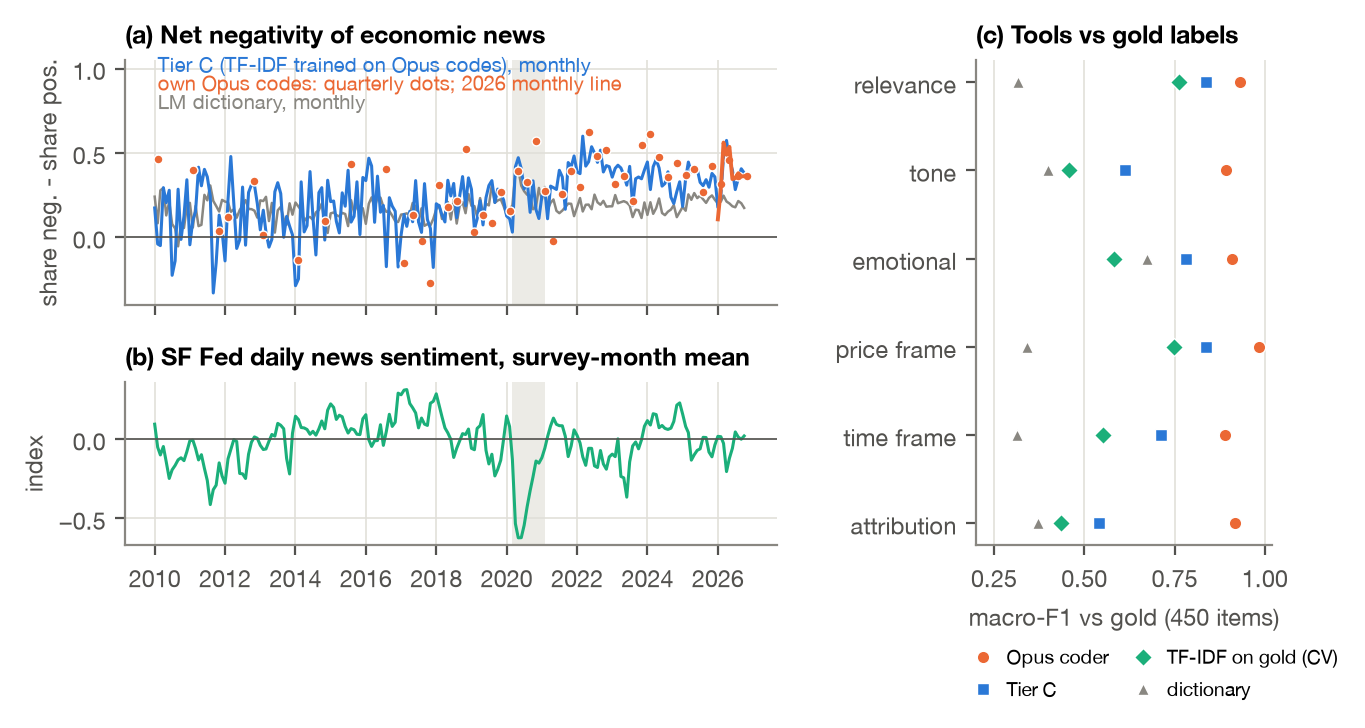

,classifier,N_train,classes,train_macro_f1,train_accuracy,cv_macro_f1,gold_macro_f1,opus_gold_macro_f1
0,relevant,8173,"{""no"": 4362, ""yes"": 3811}",0.957,0.957,0.810,0.836,0.930
1,tone,3811,"{""negative"": 1881, ""neutral"": 1115, ""positive"": 815}",0.942,0.944,0.587,0.612,0.894
2,topic:inflation_up,3811,"{""0"": 3598, ""1"": 213}",0.864,0.962,0.754,0.877,0.936
3,topic:inflation_down,3811,"{""0"": 3649, ""1"": 162}",0.925,0.986,0.714,NaN,NaN
4,topic:prices_high,3811,"{""0"": 3132, ""1"": 679}",0.944,0.965,0.846,0.884,0.976
5,topic:layoffs,3811,"{""0"": 3333, ""1"": 478}",0.913,0.956,0.785,0.818,0.962
6,topic:hiring,3811,"{""0"": 3330, ""1"": 481}",0.916,0.958,0.824,0.808,0.962


,classifier,n,cv_macro_f1
0,relevant,450,0.665
1,relevant,1000,0.727
2,relevant,2000,0.747
3,relevant,4000,0.787
4,relevant,8173,0.810
5,tone,450,0.483
6,tone,1000,0.521
7,tone,2000,0.566
8,tone,3811,0.587


{
 "TC_NEGNET": {
  "N_quarters": 50,
  "r_levels": 0.6402278321169871,
  "r_changes": 0.5292993811491101,
  "mean_tierc": 0.259988927696551,
  "mean_opus": 0.28318590954849315
 },
 "TC_prices_high": {
  "N_quarters": 50,
  "r_levels": 0.8916990064948758,
  "r_changes": 0.7193547426467829,
  "mean_tierc": 0.21312844607597295,
  "mean_opus": 0.18808768297832543
 }
}


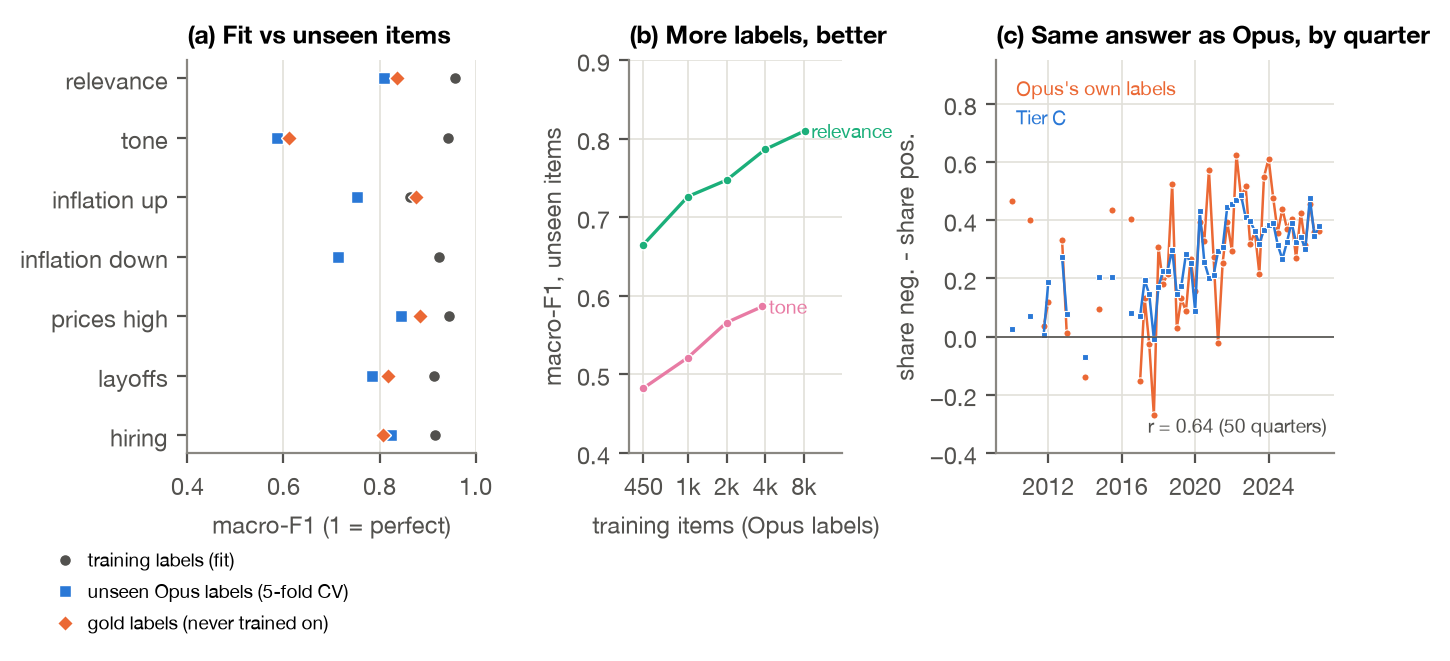

In [3]:
print(json.dumps(PREREG, indent=1)[:6000])
for t, n in PREREG_NOTES: print(t, '|', n)
display(pd.read_csv(TABLES / 'val_agreement_models_prereview.csv').round(3))   # Table 3: Sonnet vs Haiku before my corrections
display(pd.read_csv(TABLES / 'val_agreement_AB.csv').round(3))                 # the two passes after my corrections
v = pd.read_csv(TABLES / 'val_tools_vs_gold.csv')
display(v[v.subset == 'all'].pivot_table(index='field', columns='tool', values='macro_f1').round(3))
display(v[v.tool == 'opus'].pivot_table(index='field', columns='subset', values='macro_f1').round(3))
display(pd.read_csv(TABLES / 'val_per_class.csv').query("tool == 'opus'").round(3))
display(pd.read_csv(TABLES / 'val_swaps.csv').round(3))
print('test-retest kappa:', {k: round(x['kappa'], 3) for k, x in V['test_retest'].items()})
print('minimal pairs:', V['minimal_pairs'])
print(json.dumps(MED, indent=1)[:3000])
display(Image(filename=str(FIGURES / 'fig1_media.png'), width=950))
# Tier C: fit on its training labels vs unseen items, learning curve, agreement with Opus by quarter
display(pd.read_csv(TABLES / 'tierc_training.csv').round(3))
display(pd.read_csv(TABLES / 'tierc_learning_curve.csv').round(3))
print(json.dumps(TC['agreement_with_opus_quarterly'], indent=1))
display(Image(filename=str(FIGURES / 'fig2_tierc.png'), width=950))

**How the AI labels are checked.**
- **The gold set:** 450 items (180 national headlines, 120 local headlines, 150 Reddit posts; a third each from 2010 to 2019, 2020 to 2024 and 2025 to 2026), picked on text features only.
- **Who labelled it:** I couldn't find other annotators, so each of the two passes is one model's labels plus my corrections. Claude Sonnet 5.5 (pass A) and Claude Haiku 5.5 (pass B) each labelled all 450 items from the guide alone, in separate contexts; I corrected 12 items in A and 15 in B; two Claude Fable 5.1 runs settled the 163 items where the passes still differed, seeing both labels in random order without names. None of these is the Opus coder.
- **Agreement:** Cohen's kappa (plus weighted kappa and Krippendorff's alpha for tone, and Gwet's AC1 for lopsided fields). Because I corrected both passes, the reliability figure is the two models' agreement before my corrections.
- **Scoring the coder:** Opus's labels (items shown without date or outlet) are compared with the gold labels by class, by source, by period, on items where the passes agreed or disagreed, and on the 163 items with any disagreement.
- **Baselines:** the Loughran-McDonald word list with keyword rules; a TF-IDF + logistic regression classifier trained on the gold labels (5-fold cross-validation); and the same classifier trained on Opus's labels of non-gold items (Tier C).
- **Checks that need no labels:** the minimal pairs (right answers known by construction), the test-retest run and the swap tests.

## 4. Economic baseline and the sentiment gap

*Readings used:* Bolhuis, Cramer, Schulz and Summers (2024), the key paper for an economy-only sentiment model; Bybee et al. (2024) for using text only where it adds to economic data.

- **Model E (E for economy).** ICS_t = 117.2 - 4.87 U_t - 2.18 π_t + 0.87 g_t, in index points per percentage point, fitted on Jan 2010 to Dec 2019 (N = 120, R² = 0.88), each input the latest value published by day 14 of month t. Its leftover errors are stationary, so it is not two trends lining up by chance. In a dry run (fit 2010 to 2016, predict 2017 to 2019) the 95% band covered 33 of 36 months.
- **The gap.** Out of sample the model expects ICS of about 91 on average in 2026; actual ICS was 44.8 to 56.6 (average 51.2).
  - The Jan to Oct 2026 average gap is **-39.9 index points**.
  - If the 2010s relationship still held, a 10-month average gap would fall between -5.6 and +5.2 points (from the model's own resampled errors), so p < 0.0005.
  - From Feb 2021 to Oct 2026 the average gap is -27.2 points, and 93% of those 69 months lie outside the 95% band. The gap is pessimism the economy cannot explain, not proof of any bias.

![Figure 3](outputs/figures/fig3_baseline_gap.png)
*Figure 3. (a) ICS and Model E (fitted 2010 to 2019 on real-time data, dashed from 2020) with its 95% band, index points. (b) Gap = ICS minus Model E: grey in sample, orange out of sample. Grey shading: COVID window, left out (real-time GDP growth swung -33% to +33%). (c) 2026 average gap for each index and question, from its own Model E, in its own points. Panel (a) follows Bolhuis et al. (2024).*

Model E (ICS):


,coef,se_ewc,p_ewc,se_nw,p_nw
const,117.2404,2.6989,0.0000,2.2271,0.0000
U,-4.8656,0.3502,0.0000,0.2919,0.0000
pi,-2.1801,1.0982,0.0752,1.1665,0.0616
g_qoq,0.8723,0.3609,0.0363,0.3774,0.0208


ICS          R2 0.881 | 2026 gap -39.9 (null band -5.6 to 5.2, p < 0.0005) | share explained 0.159 [0.054, 0.264]
ICC          R2 0.928 | 2026 gap -55.6 (null band -5.1 to 5.1, p < 0.0005) | share explained 0.116 [0.045, 0.188]
ICE          R2 0.793 | 2026 gap -29.8 (null band -6.8 to 6.5, p < 0.0005) | share explained 0.205 [0.049, 0.360]
X1_fin_now   R2 0.941 | 2026 gap -58.7 (null band -6.5 to 6.7, p < 0.0005) | share explained 0.081 [-0.016, 0.178]
X2_fin_exp   R2 0.835 | 2026 gap -43.1 (null band -6.4 to 6.3, p < 0.0005) | share explained 0.057 [-0.012, 0.127]
X3_bus_1y    R2 0.757 | 2026 gap -46.7 (null band -15.4 to 14.3, p < 0.0005) | share explained 0.273 [0.066, 0.479]
X4_bus_5y    R2 0.651 | 2026 gap -29.6 (null band -13.4 to 11.7, p < 0.0005) | share explained 0.291 [0.080, 0.502]
X5_durables  R2 0.837 | 2026 gap -85.7 (null band -10.2 to 8.5, p < 0.0005) | share explained 0.145 [0.082, 0.207]
coverage check: {'N': 36, 'boot_coverage': 0.9166666666666666, 'analytic_coverage

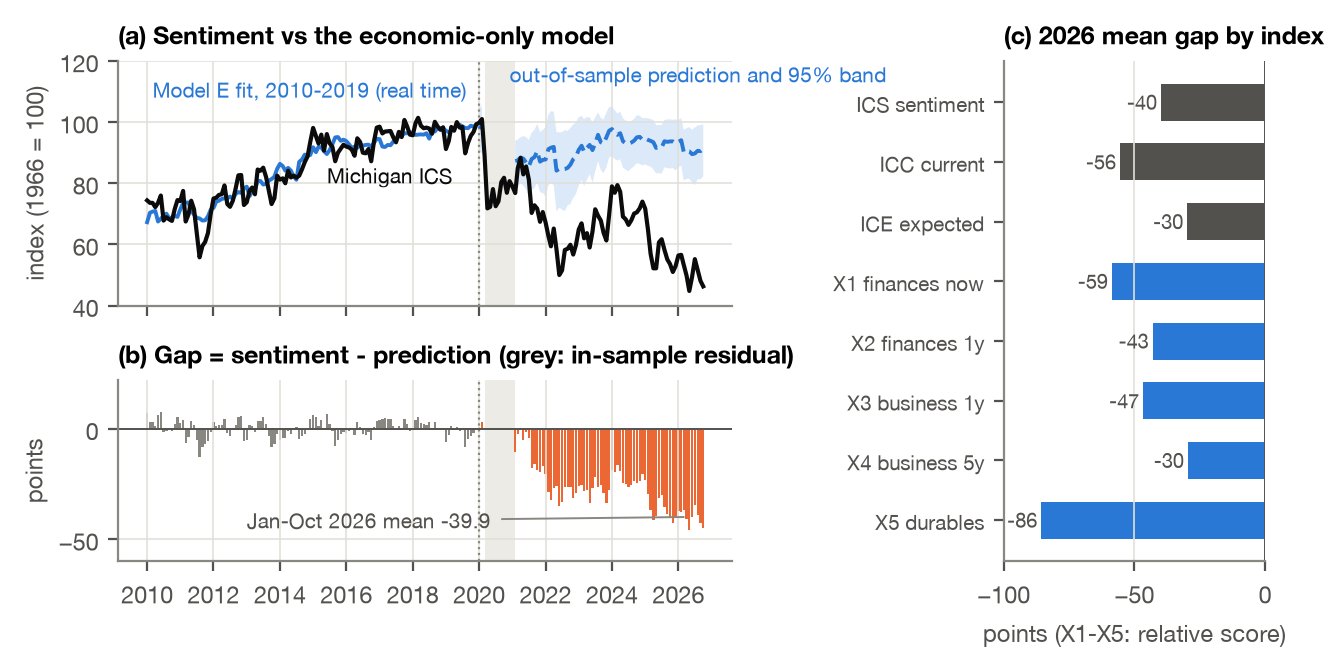

In [4]:
print('Model E (ICS):'); display(pd.DataFrame(E['E_ICS']['coef']).T.round(4))
for k in ['ICS', 'ICC', 'ICE', 'X1_fin_now', 'X2_fin_exp', 'X3_bus_1y', 'X4_bus_5y', 'X5_durables']:
    e = E[f'E_{k}']; d = e['decomposition_2019_to_2026']
    print(f"{k:12s} R2 {e['R2_train']:.3f} | 2026 gap {e['mean_gap_2026']:.1f} (null band {e['mean_gap_2026_test']['null_lo']:.1f} to {e['mean_gap_2026_test']['null_hi']:.1f}, p {e['mean_gap_2026_test']['p_text']}) | share explained {d['share_explained']:.3f} [{d['share_lo']:.3f}, {d['share_hi']:.3f}]")
print('coverage check:', E['coverage_check_2017_19'])
display(Image(filename=str(FIGURES / 'fig3_baseline_gap.png'), width=950))

**How Figure 3 is made.**
- For each survey month t, the economy is what had been published by day 14 of t (from ALFRED): the latest unemployment rate, headline PCE inflation over 12 months, and the latest quarter's real GDP growth (annualised).
- Model E is a straight-line (OLS) fit of the index on these three, over Jan 2010 to Dec 2019.
- Panel (a): the fit and, from Jan 2020, the out-of-sample prediction with a 95% band from a block bootstrap (12-month blocks, coefficients re-estimated).
- Panel (b): the gap (index minus prediction). Grey bars are in-sample errors, orange bars out-of-sample gaps.
- The COVID months (Mar 2020 to Jan 2021) are left out on purpose: real-time GDP growth of -33% to +33% would throw a straight-line prediction off the scale.
- Panel (c): the same model for the current-conditions and expectations indexes and for each of Michigan's five questions (their tables end in Aug 2026). Descriptive, except the bands.

## 5. RQ1: How can we measure bias in news coverage or social media?

*Readings used:* Sacerdote, Sehgal and Cook (2020), the key paper (coverage against a benchmark, outlet groups); Soroka (2006) and External: Gambetti, Maffei-Faccioli and Zoi (2023) for asymmetry; Harris and Sojourner (2024).

![Figure 4](outputs/figures/fig4_bias_tests.png)
*Figure 4. (a) Rise in monthly Tier C net negativity per 1 pp worsening (orange) and fall per 1 pp improvement (blue; below zero means it rose) in unemployment (3-month change) and inflation (12-month change in the 12-month rate), 90% EWC intervals; fair coverage puts both dots of a pair at the same height (N = 191 months, COVID window out). (b) Share of release-day headlines (Opus labels) that are negative, by the change in the released number. (c) Share of inflation-direction stories saying "rising", in months when published inflation fell vs rose. (d) Share of Opus-labelled news that is negative, by outlet group and president's party. (a) and (b) are tests; (c) and (d) descriptive with intervals.*

**Result.** Bias can be measured, but only one dimension at a time and against a stated benchmark. I find one clear bias (how coverage reacts to inflation), none clear in jobs or release-day coverage, mostly accurate numbers with loose definitions, and outlet differences that fit political lean (descriptive).
1. **Negativity asymmetry (benchmark: equal good and bad news).**
   - Inflation: net negativity rises 0.057 per 1 pp rise in inflation, but when inflation falls 1 pp it rises 0.045 instead of falling. Asymmetry p = 0.002 (0.019 without 2020 to 2021). The SF Fed index shows the same, more weakly (p = 0.10).
   - Unemployment: bad news moves net negativity 0.30 per pp, good news 0.10, not significantly different (p = 0.20).
2. **Selection (benchmark: what the data did).**
   - In months when published inflation fell, 33% of inflation-direction stories (26 of 78) still said it was rising; in rising months, 41% said it was falling. So which stories run is roughly balanced; the bias is in tone.
   - Layoff stories are 53% of layoff-or-hiring stories, while official layoffs are 25% of layoffs plus hires (JOLTS); the two do not move together (r = -0.11).
3. **Release days and accuracy (benchmark: the official release).**
   - Jobs days: 24% to 28% of headlines are negative when unemployment fell or held, 56% after a rise of 0.2 pp or more; no detectable asymmetry between +0.1 and -0.1 pp moves (p = 0.35). CPI days: no asymmetry (p = 0.15).
   - 83% of 161 numerical claims match the official figure published that day: unemployment 90%, payrolls 87%, inflation 65%. Only 10% say which measure they mean (CPI, PCE, core).
4. **Outlet groups and attribution (benchmark: center outlets, same month).** Right-leaning outlets are 9.7 percentage points more likely to be negative (p = 0.001) and Reddit 10.5 points (p < 0.001); left and local outlets do not differ. Split by the party in the White House, right-leaning outlets run 15.9 points darker than center outlets under Democratic presidents (p < 0.001) and 6.0 under Republican ones (p = 0.11; difference p = 0.07), and Reddit 12.0 under Republicans (p = 0.004). Blame on the president shows no partisan pattern (difference-in-differences in the share of items blaming the president: +0.03, 95% CI -0.07 to +0.07), from only three changes of president.
5. **Framing (descriptive).** Price stories stress price levels over rates in every group. Household framing rose from 9% to 19% of items a year before 2020 to 31% to 33% in 2022 to 2024. Right-leaning outlets use emotional wording most (33% of items, others 13% to 14%, Reddit 25%).

*Against Sacerdote et al. (2020):* they find stories about rising COVID cases outnumbering falling-case stories 5.3 to 1 even when cases fell. My inflation ratio in falling months is 0.5 to 1 (26 up vs 52 down): economic news does report improvement, just less than worsening, and the bias shows in tone more than in which stories run. Unlike them, I find right-leaning outlets more negative.

*Why this result:* with inflation, "good news" is ambiguous: a lower rate still means higher prices, so a cooling-inflation story is often written around prices still being high, which the coder rightly marks negative. For jobs, Gambetti et al. (2023) show apparent negativity bias can come from unemployment rising faster than it falls. Inflation numbers fail the accuracy check most because headlines mix CPI and PCE, or monthly and yearly changes: a definition problem more than a false number.

**In short.** Against fair benchmarks, economic news turns darker when inflation rises and does not brighten when it cools, while which stories run is roughly balanced. Jobs news shows no detectable tone asymmetry (though layoff stories are over-represented against official data) and most numbers are right. That is selective framing of inflation in tone, not a general negativity bias.

{
 "TC_NEGNET|all": {
  "N": 191,
  "nu": 13,
  "R2": 0.11849357285004347,
  "U": {
   "resp_bad": 0.3032085046995856,
   "resp_good": 0.1022210450713729,
   "se_bad": 0.15699462582802515,
   "se_good": 0.10437856671952485,
   "asym": 0.20098745962821268,
   "se_asym": 0.23403009120326665,
   "t": 0.8588103290257884,
   "p_one_sided": 0.20300124106388218,
   "ci90": [
    -0.21346424454950585,
    0.6154391638059312
   ]
  },
  "pi": {
   "resp_bad": 0.056691296412838696,
   "resp_good": -0.04452475484374134,
   "se_bad": 0.025135863044262883,
   "se_good": 0.015383368468321095,
   "asym": 0.10121605125658004,
   "se_asym": 0.028914758881168262,
   "t": 3.5004978486090885,
   "p_one_sided": 0.001955155676857445,
   "ci90": [
    0.05000993911701114,
    0.15242216339614895
   ]
  }
 },
 "TC_NEGNET|ex_2020_21": {
  "N": 180,
  "nu": 13,
  "R2": 0.1287873720596593,
  "U": {
   "resp_bad": 0.23255189162088247,
   "resp_good": 0.21133851278522664,
   "se_bad": 0.16373353601367854,
   "se_g

,release,bin,items,releases,neg,pos,emo
0,cpi,<=-0.2,80,47,0.300,0.312,0.075
1,cpi,-0.1,50,21,0.340,0.280,0.100
2,cpi,0,45,18,0.467,0.133,0.089
3,cpi,+0.1,34,18,0.324,0.206,0.029
4,cpi,>=+0.2,104,54,0.529,0.115,0.163
5,jobs,<=-0.2,98,47,0.276,0.520,0.071
6,jobs,-0.1,97,43,0.237,0.464,0.062
7,jobs,0,114,48,0.254,0.482,0.123
8,jobs,+0.1,92,36,0.370,0.370,0.120
9,jobs,>=+0.2,32,13,0.562,0.156,0.188


{
 "jobs": {
  "neg_shift_bad_0.1": 0.11517925247902364,
  "neg_shift_good_0.1": -0.01727256285042652,
  "asym_sum": 0.09790668962859711,
  "p_two_sided": 0.34667525278199207,
  "N_items": 433,
  "releases": 187
 },
 "jobs_noise_band": {
  "emotional_small_changes": 0.10231023102310231,
  "emotional_large_changes": 0.1,
  "n_small": 303,
  "n_large": 130
 },
 "cpi": {
  "neg_shift_bad_0.1": -0.14313725490196097,
  "neg_shift_good_0.1": -0.12666666666666657,
  "asym_sum": -0.26980392156862754,
  "p_two_sided": 0.14911948859564617,
  "N_items": 313,
  "releases": 158
 }
}
{
 "claims": 161,
 "match_rate": 0.8260869565217391,
 "match_rate_rounding_rule": 0.8571428571428571,
 "by_indicator_rounding_rule": {
  "gdp_growth": {
   "mean": 1.0,
   "size": 2
  },
  "inflation": {
   "mean": 0.65,
   "size": 40
  },
  "payrolls": {
   "mean": 0.942,
   "size": 69
  },
  "unemployment_rate": {
   "mean": 0.9,
   "size": 50
  }
 },
 "by_indicator": {
  "gdp_growth": {
   "mean": 1.0,
   "size": 2
 

BLAME_PRES                      CREDIT_PRES                      ATTR_ANY                     
group     center   left  local  right      center   left  local  right   center   left  local  right
pres                                                                                                
D          0.022  0.008  0.012  0.054       0.007  0.022  0.004  0.015    0.113  0.095  0.083  0.112
R          0.040  0.044  0.049  0.058       0.025  0.029  0.034  0.081    0.158  0.197  0.172  0.310

,neg,pos,NEGNET,EMO,LEVEL,HH,FC,N1,N2,N3,N4
group,,,,,,,,,,,
center,0.484,0.204,0.280,0.137,0.519,0.104,0.271,0.109,0.055,0.116,0.094
left,0.476,0.172,0.304,0.137,0.795,0.211,0.220,0.191,0.036,0.131,0.083
local,0.504,0.272,0.231,0.127,0.898,0.256,0.210,0.210,0.023,0.166,0.161
reddit,0.601,0.099,0.502,0.252,0.682,0.227,0.226,0.148,0.016,0.157,0.047
right,0.602,0.179,0.423,0.328,0.855,0.249,0.202,0.285,0.049,0.171,0.070


{
 "D|center": {
  "neg_share": 0.48363636363636364,
  "n": 275
 },
 "D|left": {
  "neg_share": 0.4720670391061452,
  "n": 358
 },
 "D|local": {
  "neg_share": 0.4583333333333333,
  "n": 240
 },
 "D|right": {
  "neg_share": 0.6439024390243903,
  "n": 205
 },
 "R|center": {
  "neg_share": 0.484472049689441,
  "n": 322
 },
 "R|left": {
  "neg_share": 0.4793187347931874,
  "n": 411
 },
 "R|local": {
  "neg_share": 0.5368098159509203,
  "n": 326
 },
 "R|right": {
  "neg_share": 0.5741935483870968,
  "n": 310
 }
}
{
 "left": {
  "coef": -0.010777437324673822,
  "p": 0.6973438470067871
 },
 "local": {
  "coef": 0.0018132896750690242,
  "p": 0.9521836458067926
 },
 "reddit": {
  "coef": 0.10493007155338847,
  "p": 0.00028231946300217664
 },
 "right": {
  "coef": 0.09725101191275153,
  "p": 0.0014073243071947383
 }
}


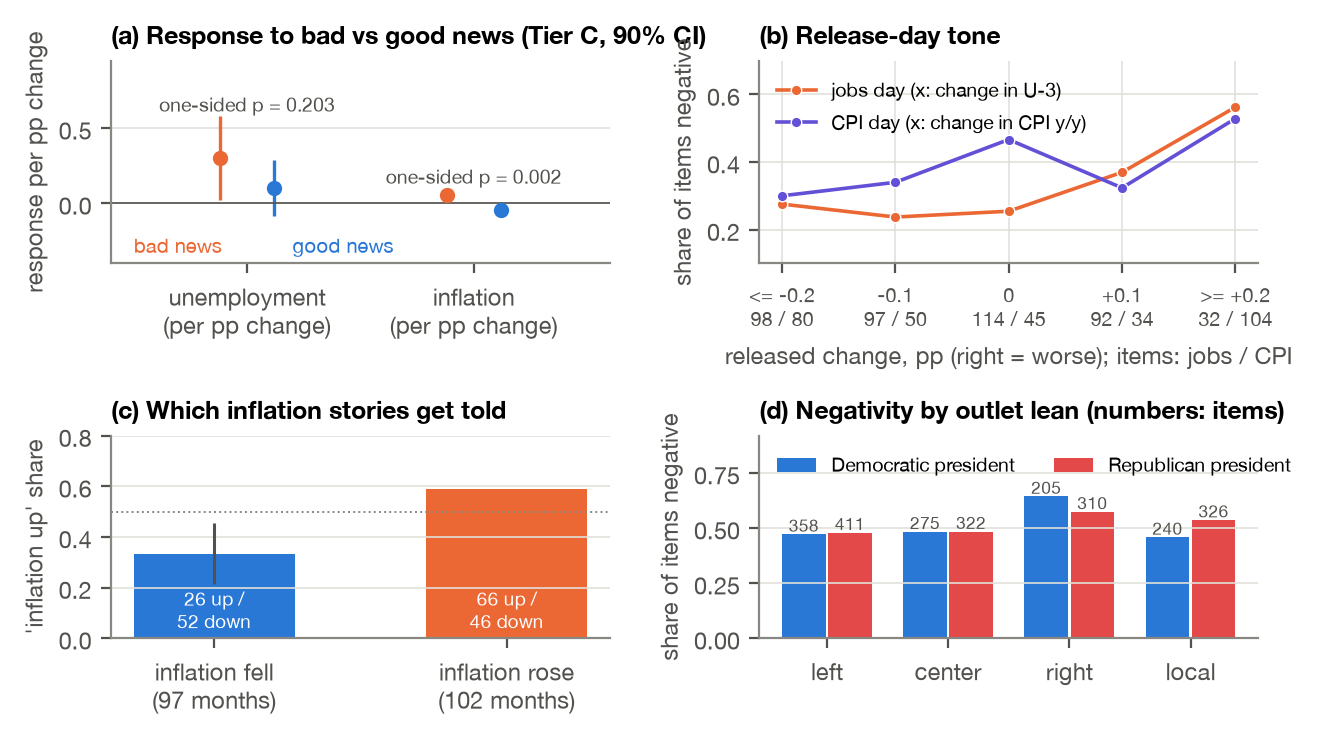

In [5]:
print(json.dumps(R['rq1']['asymmetry'], indent=1)[:4000])
print(json.dumps(R['rq1']['selection'], indent=1))
display(pd.read_csv(TABLES / 'rq1_release_bins.csv').round(3))
print(json.dumps(R['rq1']['release_days'], indent=1)); print(json.dumps(R['rq1']['calibration'], indent=1))
display(pd.read_csv(TABLES / 'rq1_attribution.csv', header=[0, 1], index_col=0).round(3))
display(pd.read_csv(TABLES / 'rq1_by_source_group.csv', index_col=0).round(3))
print(json.dumps(R['rq1']['neg_by_lean_and_president'], indent=1)); print(json.dumps(R['rq1']['lpm_negative_by_group'], indent=1))
display(Image(filename=str(FIGURES / 'fig4_bias_tests.png'), width=950))

**How the bias measures are computed.**
- Tests on individual headlines (selection, release days, number accuracy, attribution, outlet groups) use only headlines Opus judged relevant. The monthly Tier C series uses the relevance and tone from the classifier trained on Opus's labels.
- A survey month's news runs from the 15th of the previous month to the 14th, so it ends at the prediction date.
- A month's news measure is the plain average over four outlet groups (left-leaning, center and right-leaning national, and local) of each group's share. The weights are fixed, so nothing depends on later data. Tone = share negative minus share positive.
- **Asymmetry test:** monthly tone is regressed on the rise and the fall of unemployment (3-month change) and of inflation (12-month change in the 12-month rate), separately. The reaction to bad news is the coefficient on the rise; the reaction to good news is minus the coefficient on the fall. Negativity bias means the first is bigger (one-sided test).
- **Release days:** tone of headlines on the day of and the day after each jobs or CPI release, grouped by how much the released number changed.
- **Number accuracy:** each number in a headline is compared with the official figure published by that day.

## 6. RQ2: How can we determine the impact of such bias on Michigan sentiment?

*Readings used:* Shapiro, Sudhof and Wilson (2022), the key paper; Souza et al. (2015) for Granger tests both ways; Doms and Morin (2004); External: Toda and Yamamoto (1995), Cinelli and Hazlett (2020), Gentzkow and Shapiro (2010). Figure 1 shows the media series used.

**Result.** With 17 years of monthly data I cannot detect a depressing effect of negative news on sentiment that passes the rule set in advance, and the most it could explain, even if fully causal, is small next to the gap. This is about what is detectable, not proof that media do not matter.
- **News vs sentiment, economy held fixed.** ICS on the economy, the six household costs and Tier C net negativity (N = 191 months).
  - Coefficient: -6.17 index points per 1.0 of net negativity (about -0.6 per 0.1), one-sided p = 0.12, q = 0.18.
  - If causal: Tier C net negativity rose 0.16 from 2019 to 2026, so it explains -1.0 index point of the -39.9-point gap (90% CI -2.4 to +0.4).
  - Without the household costs (so the news also gets credit for the pressures it reports): -14.7 per 1.0 (one-sided p = 0.061), about -2.4 points if causal (90% CI -4.9 to +0.2).
  - Fragile: a hidden factor explaining 12% of what is left of both would wipe it out (robustness value 0.12).
  - The claim rule fails: the sign and a shuffle test pass, but q, the household costs, dropping any one year and dropping 2021 to 2022 do not.
  - In month-to-month changes the sign flips (+0.21 index points per 1.0, p = 0.89).
- **SF Fed index.** +22.4 index points per index unit (q = 0.010; survives every check). But it barely moved from 2019 to 2026 (+0.03), so it explains +0.6 points, the opposite direction to the gap.
- **The original Opus measure, by quarter** (N = 47): -23.8 points per 1.0 with the economy only (p = 0.050), +0.44 once household costs enter (p = 0.96).
- **Forecast misses.** The economy-only forecast misses of 2017 to 2026 (index points) correlate -0.58 with Tier C net negativity (p = 0.003, N = 107): darker-news months are months gloomier than the economy predicts. But both trend after 2021, and with household costs the link goes away.
- **Which moves first.** Tier C to sentiment: p = 0.057 (q = 0.115); sentiment to Tier C: p = 0.67. SF Fed to sentiment: p = 0.80; **sentiment to SF Fed: p = 0.0005 (q = 0.003)**: past sentiment helps predict the index, not the reverse.
- **Demand for bad news.** Within the same subreddit and month, negative Reddit posts get 0.86 more log points of upvotes (about 2.4 times; p = 0.003, N = 616): audiences reward negativity (engagement, not exposure).
- **Party timing.** From October to December 2024, Democrats' ICS fell 21.8 points and Republicans' rose 31.8, while unemployment moved +0.1 pp and inflation +0.07 pp. Right-leaning outlets' net negativity (-1 to +1) went from 0.42 to 0.34 and left-leaning from 0.22 to 0.27 (3-month windows); 2020 cells are too small.

*Against Shapiro et al. (2022):* they find news sentiment predicts Michigan sentiment (correlation 0.58). I find the same kind of link out of sample, and their index stays significant with my controls. But over my sample sentiment moves before their index, and Tier C's link does not survive household costs.

*Why this result:* common shocks (gas prices and tariffs move both news and sentiment), reverse causation (sentiment moves first; audiences reward bad news) and noise in monthly tone (Tier C tone F1 0.61, which pulls toward zero). Household costs absorb most of the Tier C link, as expected if news mostly reports the same pressures people feel.

**How a causal answer would be obtained (the design I propose).**
- **Design.** A randomized framing experiment, written down in advance, IRB approval first, with about 4,000 consenting US adults (e.g. a probability panel such as NORC AmeriSpeak).
- **Arms**, all truthful, from the same official numbers: (1) neutral summary of the latest CPI, jobs and GDP; (2) price level ("prices are 25% higher than in 2020"); (3) rate ("inflation slowed to 3%"); (4) a typical family's budget; (5) control, no economic text.
- **Outcomes.** Michigan's five questions word for word, scored as in the index, plus inflation expectations and a recall item; party, income and news diet measured first; a two-week follow-up for fading.
- **Size.** 800 per arm detects a 3.5-index-point difference between two arms (80% power, 5% level, assumed spread 25 points). Detecting 2.4 points, the upper bound above, needs about 1,700 per arm.
- **From the sample to the national index.** Needs (a) how many people actually meet each frame, (b) weights to Michigan's mix of age, income, region and party, (c) the same effect within groups or modelled differences, (d) a one-time vignette that behaves like months of exposure, (e) no spill-over. National effect ≈ Σ over groups of share × exposure rate × effect.
- Natural experiments (local paper closures; regional coverage vs regional sentiment) are possible, but local groups are thin.

**In short.** News tone and sentiment move together, but taken as causal Tier C explains about 1 of the 40 points, the SF Fed index points the wrong way, and sentiment leads that index. A proper impact estimate needs randomized framing plus exposure data.

In [6]:
display(pd.read_csv(TABLES / 'rq2_family.csv').round(4))
display(pd.read_csv(TABLES / 'rq2_toda_yamamoto.csv').round(4))
print('claim rule (Tier C):', R['rq2']['claim_rule_TC_NEGNET']); print('MDE:', R['rq2']['mde'])
print('own-Opus quarterly (the original measure at its fallback frequency):', R['rq2']['quarterly_own_opus'])
print({k: v for k, v in R['rq2'].items() if k.startswith('oos_gap') or k == 'reddit_demand'})
print(json.dumps(R['rq2']['party_timing'], indent=1)[:3000])

,test,media,N,nu,coef,se,p_two_sided,p_expected_sign,expected_sign,implied_contribution_if_causal,implied_ci90,media_change_2019_2026,robustness_value,loyo_min_coef,loyo_max_coef,loyo_max_p,drop_2021_22_coef,drop_2021_22_p,bh_q
0,level: S on econ + H1 + TC_NEGNET,TC_NEGNET,191,13.0,-6.1719,5.0460,0.2430,0.1215,-1,-0.9877,"[np.float64(-2.4177566515991247), np.float64(0.442366199125395)]",0.1600,0.1193,-8.7963,-3.2207,0.4361,-2.9169,0.4662,0.1822
1,"changes: dS on dU, dpi, dg, dTC_NEGNET",TC_NEGNET,189,NaN,0.2147,NaN,0.8860,0.5570,-1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,level: S on econ + H1 + SFFED,SFFED,191,13.0,22.4286,6.9805,0.0068,0.0034,1,0.6234,"[np.float64(0.27982051818907566), np.float64(0.9670776920836387)]",0.0278,0.2908,17.6816,27.3003,0.0192,29.0124,0.0004,0.0102
3,"changes: dS on dU, dpi, dg, dSFFED",SFFED,189,NaN,12.9017,NaN,0.0038,0.0019,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,test,lag_p,N,wald,p,sum_coef,p_perm,n_shifts,bh_q
0,TY: TC_NEGNET -> S,1,187,3.6084,0.0575,-3.1775,0.0964,165,0.1150
1,TY: S -> TC_NEGNET,1,187,0.1832,0.6687,-0.0014,0.6687,165,0.8024
2,TY: SFFED -> S,1,187,0.0610,0.8049,-0.9787,0.8373,165,0.8049
3,TY: S -> SFFED,2,185,15.3269,0.0005,0.0018,0.0060,165,0.0028


claim rule (Tier C): {'expected_sign': True, 'bh_q_lt_0.10': False, 'permutation_p_lt_0.10': True, 'survives_h1_controls': False, 'survives_loyo': False, 'survives_drop_2021_22': False, 'passes': False}
MDE: {'N': 107, 'rho_x': 0.902282406040841, 'rho_y': 0.5822944268430549, 'N_eff': 33.291621501420515, 'mde_r': 0.46918834443684565}
own-Opus quarterly (the original measure at its fallback frequency): {'N_quarters': 47, 'nu': 5, 'coef_with_H1': 0.4383866351110868, 'p_with_H1': 0.9562905767603889, 'coef_econ_only': -23.847095868944812, 'p_econ_only': 0.05036977121354802}
{'oos_gap_on_own_rt': {'N': 107, 'coef': -43.90155000203262, 'p': 0.003372488140564789, 'r': -0.5784972347945456}, 'oos_gap_on_own': {'N': 107, 'coef': -37.2421805892688, 'p': 0.005565810059245058, 'r': -0.5093927169253281}, 'oos_gap_on_sf': {'N': 107, 'coef': 25.756168828713207, 'p': 0.13681917756568573, 'r': 0.336740914178658}, 'reddit_demand': {'N': 616, 'coef_neg_log_score': 0.8610370504866036, 'p': 0.003432405342976

## 7. RQ3: How much of the gap can unemployment, inflation and real GDP growth explain?

*Readings used:* Bolhuis et al. (2024), the key paper; External: Stantcheva (2024) on why people dislike inflation; Malmendier and Nagel (2016). Figure 3(c).

**Result.** About a sixth.
- **The decomposition.** From the 2019 average (96.0) to the Jan to Oct 2026 average (51.2), ICS fell 44.8 points. Unemployment rose 0.56 pp, inflation 1.82 pp and growth fell 0.51 pp, which Model E turns into a predicted fall of 7.1 points: **16% of the actual fall (95% CI 5% to 26%)**. Inflation accounts for 4.0 points, unemployment 2.7, growth 0.4.
- **The gap sits in households' own finances.** Model E explains only 6% to 8% of the fall in personal finances (X1, X2) and 14% in buying conditions for big items (X5), against 27% to 29% for business conditions (X3, X4).
- **Robust to how the economy is measured.** Yearly GDP growth, core PCE, CPI, start-of-month data, revised data and a quarterly model all give a 2026 gap of -39.7 to -41.7 points.
- **Household costs do not close it.** Added to the 2010 to 2019 model, alone or together, they leave the 2026 gap between -39.9 and -43.8 points (all six: p = 0.46). In a long sample (1992 to 2019) three of them close 6% of that model's own 2026 gap (-41.0 points), because historically high mortgage rates came with booms.

*Against Bolhuis et al. (2024):* their model leaves a similar gap in 2023, and an inflation measure that includes borrowing costs closes almost three quarters of it. My mortgage-rate and affordability controls do not; their result needs their cost-of-money price index, which I did not build.

*Why this result:* a linear model learns how sentiment moved with the *rate* of inflation in a decade when the price *level* never jumped. In 2026 the PCE price level was about 14% above its 2010 to 2019 trend, and falling inflation leaves that level in place: in Aug 2026, 53% of respondents said they were worse off because of higher prices, against 6% to 9% in 2019. And while GDP grew, real disposable income per head grew only -1.4% to +1.4% year on year during 2026, and the 30-year mortgage rate rose from 6.2% in January to 7.4% in October 2026 (3.9% in 2019).

**In short.** The headline numbers explain about a sixth of the fall; the rest sits in personal finances and buying conditions, which points to price levels and borrowing costs that a 2010s model cannot price.

In [7]:
display(pd.read_csv(TABLES / 'rq3_h1_controls_2010_19.csv').round(3))
display(pd.read_csv(TABLES / 'rq3_h1_controls_long.csv').round(3))
print(json.dumps(E['variants'], indent=1)); print('revision effect share:', E['h3_revision_effect_share'])
print('seasonality:', E['seasonality']); print('rolling sign changes:', E['rolling_sign_changes'], E['expanding_vs_fixed_rmse_post'])
display(pd.read_csv(TABLES / 'rq3_group_gaps.csv', index_col=0).round(2))

,controls,R2_train,mean_gap_2026,share_2026_gap_closed,mean_gap_post,wald_F_ewc,wald_p_ewc,wald_p_nw,coef,bh_q_ewc
0,pi36,0.881,-40.595,-0.018,-28.238,0.052,0.825,0.810,{'pi36': 0.1827},0.825
1,rdpi_yoy,0.881,-39.926,-0.001,-27.196,0.188,0.674,0.668,{'rdpi_yoy': -0.1781},0.809
2,mort30,0.883,-43.424,-0.089,-29.534,1.775,0.212,0.140,{'mort30': 1.5601},0.622
3,afford,0.883,-43.835,-0.099,-30.566,1.139,0.311,0.235,{'afford': 0.0815},0.622
4,U6_gap,0.883,-40.074,-0.005,-27.437,0.657,0.437,0.324,{'U6_gap': -1.7797},0.655
5,dsr,0.889,-42.557,-0.067,-26.803,5.029,0.049,0.005,{'dsr': 2.5408},0.293
6,pi36+rdpi_yoy+mort30+afford+U6_gap+dsr,0.893,-43.168,-0.082,-23.992,1.111,0.464,0.002,"{'pi36': 0.3205, 'rdpi_yoy': -0.3757, 'mort30': 3.4876, 'afford': -0.2201, '...",NaN


,controls,N_train,nu,R2_train,mean_gap_2026,share_2026_gap_closed,mean_gap_post,n_post,wald_p_ewc,wald_p_nw,coef
0,base,336,19,0.700,-41.013,0.000,-26.149,68,NaN,NaN,"{'U': -5.2398, 'pi_cpi': -3.259, 'g_qoq': 2.2667}"
1,pi36_cpi,336,19,0.701,-40.871,0.003,-25.709,68,0.662,0.635,"{'U': -5.2124, 'pi_cpi': -3.0568, 'g_qoq': 2.2516, 'pi36_cpi': -0.1509}"
2,mort30,336,19,0.739,-41.028,-0.000,-23.790,68,0.002,0.000,"{'U': -5.094, 'pi_cpi': -4.1972, 'g_qoq': 2.0751, 'mort30': 1.71}"
3,afford,336,19,0.700,-41.087,-0.002,-26.088,68,0.816,0.793,"{'U': -5.2146, 'pi_cpi': -3.3363, 'g_qoq': 2.2633, 'afford': 0.0075}"
4,pi36_cpi+mort30+afford,336,19,0.805,-38.454,0.062,-17.757,68,0.001,0.000,"{'U': -5.1553, 'pi_cpi': -2.5851, 'g_qoq': 1.714, 'pi36_cpi': -1.1739, 'mort..."


{
 "g_yoy": {
  "R2_train": 0.870986767034562,
  "mean_gap_2026": -40.846584729541426,
  "mean_gap_post": -27.580920172276272
 },
 "core_pce": {
  "R2_train": 0.8718632129072447,
  "mean_gap_2026": -40.01908285595501,
  "mean_gap_post": -27.014871771956553
 },
 "cpi": {
  "R2_train": 0.8810453624087838,
  "mean_gap_2026": -41.68616955993323,
  "mean_gap_post": -27.99738897509569
 },
 "start_of_month_info": {
  "R2_train": 0.8749959456604248,
  "mean_gap_2026": -39.74128480056474,
  "mean_gap_post": -27.014315382773272
 },
 "revised_data": {
  "R2_train": 0.873080788403527,
  "mean_gap_2026": -41.00904571192683,
  "mean_gap_post": -28.01454669823733
 },
 "quarterly": {
  "N_train": 40,
  "R2_train": 0.9185046452692541,
  "mean_gap_2026_Q1_Q3": -40.30169971934177
 }
}
revision effect share: 0.02805631413390806
seasonality: {'p_nw_month_dummies': 0.0007284320165904523, 'note': '11 restrictions > nu, EWC F undefined'}
rolling sign changes: {'U': 2, 'pi': 2, 'g_qoq': 6} {'expanding': 16.616

,R2_train,mean_gap_2026_jan_aug
ICS_bottom,0.81,-38.35
ICS_middle,0.84,-41.57
ICS_top,0.81,-36.62
ICS_age18_34,0.72,-38.41
ICS_age35_54,0.84,-45.12
ICS_age55p,0.83,-38.04
ICS_NE,0.77,-32.78
ICS_MW,0.83,-38.78
ICS_S,0.87,-40.56
ICS_W,0.77,-41.10


## 8. RQ4: Which perceptual mechanisms can the data actually measure?

*Readings used:* Soroka (2006); External: D'Acunto, Malmendier, Ospina and Weber (2021); Malmendier and Nagel (2016); Carroll (2003); Mian, Sufi and Khoshkhou (2023). Apart from the public-side asymmetry test (pre-registered with RQ1), these were planned before testing but not written into the pre-registration, so they are exploratory.

![Figure 5](outputs/figures/fig5_mechanisms.png)
*Figure 5. (a) Share worse off because of higher prices (%, Michigan Table 7) against the PCE price level relative to its 2010 to 2019 trend (%, lagged two months), COVID window out. (b) Recall of bad news about high prices (Table 24) and the Tier C "prices high" share of coverage, each standardised over 2010 to 2026. (c) ICS by party (index points); dotted lines: 2016, 2020, 2024 elections. Descriptive.*

**Result.** Four mechanisms can be measured (negativity bias in coverage and in the public, price-level anchoring, partisan switching), two only partly (demand for negativity, availability), experience effects only weakly, and an individual's confirmation or availability bias not at all.

**Table 6. Mechanisms: measure, result, verdict.**

| Mechanism | Measure | Result | Verdict |
|---|---|---|---|
| Negativity bias, coverage | Asymmetry of net negativity (Figure 4a) | Inflation yes (p = 0.002); unemployment no (p = 0.20) | Measurable |
| Negativity bias, public | Same test on ICS | A 1 pp rise in inflation lowers ICS 6.2 points; a 1 pp fall changes it by -2.9 points instead of raising it (p = 0.018); unemployment p = 0.11 | Measurable (pre-registered) |
| Negativity bias, demand | Reddit upvotes; recalled news (Table 23) | Negative posts get about 2.4 times the upvotes; recalled bad news rises with inflation, does not fall back (p = 0.038) | Partly (engagement is not exposure) |
| Availability | Recall of price news (Table 24) vs coverage; gas | Correlation 0.78, but recall moves before coverage (p = 0.0001), not after (p = 0.43); gas prices add nothing to Model E (p = 0.22) | Partly |
| Anchoring on the price level | "Worse off because of prices" vs inflation rate, 36-month inflation, level vs trend | R² 0.41 (rate), 0.66 (36-month), **0.81 (level)**; worse off: 7% (2019), 40% (2022), 51% (2026) | Measurable |
| Partisan filter | Party ICS around elections with the economy flat; outlet tone | 2024: Democrats -21.8, Republicans +31.8 points in two months; outlet net negativity moved less than 0.08 (on -1 to +1) | Switching measurable; individual bias not |
| Experience effects | 2026 gap by age | 18 to 34: -38.4; 35 to 54: -45.1; 55+: -38.0 points: no age order | Weak |
| Not measurable | Which stories a respondent saw and believed | No data link news to respondents | Needs the experiment or a panel |

*Against Soroka (2006):* he finds asymmetry in UK coverage and in the public. I find the same for US inflation, on both sides, and on neither side for unemployment.

*Why this result:* the price level reaches people through every bill, so a level that stays high keeps "worse off because of prices" high even as inflation cools (partly a contrast between periods, since the level gap is near zero by construction in 2010 to 2019). Coverage behaves the other way: "prices high" coverage follows the inflation rate (R² 0.35) more than the level (0.27), so the media move on when inflation cools while households do not. And people report hearing about high prices before coverage rises, which fits experience at the till driving both.

**In short.** What the data can see (inflation negativity, level anchoring, party switching) points to prices and party more than to coverage. Whether any reader's beliefs were bent by what they read cannot be measured from text.

{
 "recall_asymmetry": {
  "N": 189,
  "nu": 13,
  "R2": 0.17112335460044836,
  "U": {
   "resp_bad": 56.76375461652769,
   "resp_good": 30.043595921619897,
   "se_bad": 29.75760932994162,
   "se_good": 22.43843043277023,
   "asym": 26.720158694907795,
   "se_asym": 43.36786182025649,
   "t": 0.6161281090050698,
   "p_one_sided": 0.2742234973632006,
   "ci90": [
    -50.08143611512848,
    103.52175350494407
   ]
  },
  "pi": {
   "resp_bad": 12.835161859642941,
   "resp_good": -3.321929912006284,
   "se_bad": 3.6845357230401286,
   "se_good": 5.870591948668906,
   "asym": 16.157091771649224,
   "se_asym": 8.392244570946893,
   "t": 1.925240814308898,
   "p_one_sided": 0.03817921862674167,
   "ci90": [
    1.2949855936698462,
    31.0191979496286
   ]
  }
 },
 "availability_recall_vs_media": {
  "N": 189,
  "corr_levels": 0.7799786232081545,
  "corr_changes": 0.3891844553142988,
  "ty_media_to_recall": {
   "lag_p": 1,
   "N": 185,
   "wald": 0.635830898379256,
   "p": 0.42522453376764

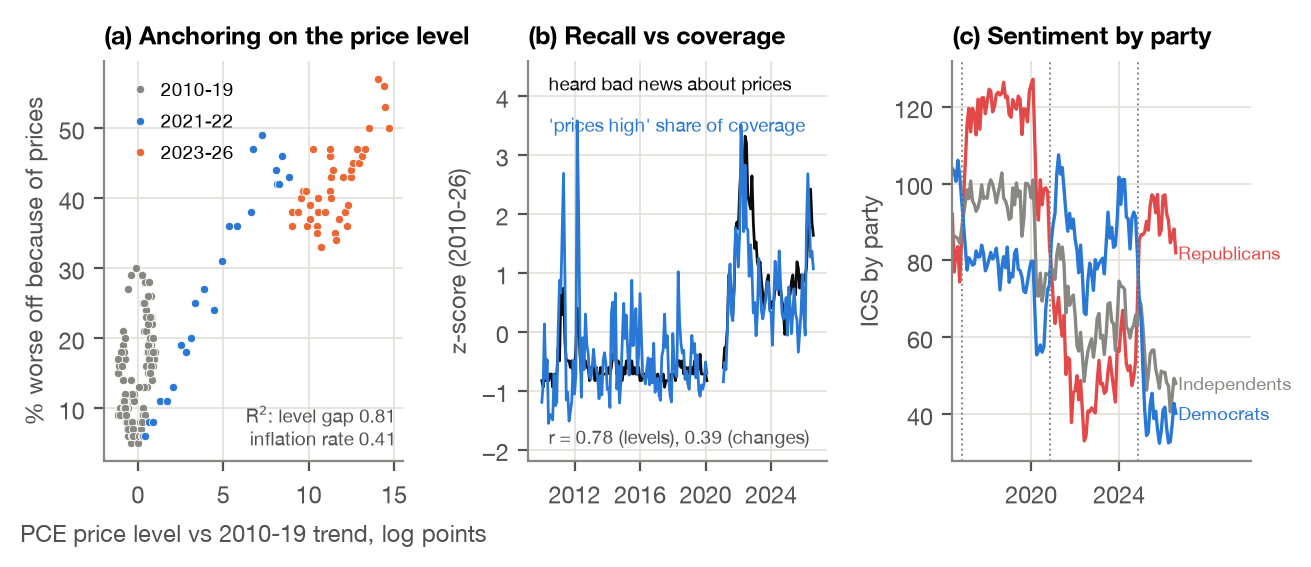

In [8]:
print(json.dumps(R['rq4'], indent=1)[:5000])
display(Image(filename=str(FIGURES / 'fig5_mechanisms.png'), width=950))

## 9. RQ5: Does media analysis improve predictions of consumer sentiment beyond economic indicators?

*Readings used:* Shapiro, Sudhof and Wilson (2022), the key paper; Bybee et al. (2024); Jurafsky slides on O'Connor et al. (2010); External: Clark and West (2007), Diebold and Mariano (1995), Harvey, Leybourne and Newbold (1997).

**Result.** News improves forecasts a little over the economy alone (borderline); with household costs in, a similar gain just misses the 0.10 bar except with a rolling window. Household costs improve forecasts a lot.
- **The models.** The brief's three: m1 economy only; m2 economy + Tier C news (net negativity and inflation-up share); m3 economy + news + household costs (the brief allows household or political controls; party is handled in Section 11). I add m1b, economy + household costs, to isolate the controls.
- **How.** For each month from Jan 2017 to Oct 2026 (107 months), each model is re-fitted on all earlier months and predicts that month from data published by day 14; Tier C is re-trained each month on labels available then.
- **Typical miss (RMSE, index points).** m1 13.5, m2 13.1, m1b 9.2, m3 9.0.
  - m2 vs m1: 3% smaller misses, Clark-West p = 0.053 (rolling 84-month window p = 0.028; with last month's sentiment in both, p = 0.13).
  - m3 vs m1b: 2% smaller, p = 0.10 (rolling 0.047).
  - m1b vs m1 (exploratory): 32% smaller, p = 0.001.
- **Example, March 2026 (actual 53.3).** Model E, fixed on 2010 to 2019, predicted 90.2. The updating forecasts: m1 76.2, m2 73.5, m1b 71.8, m3 70.7. News moved the forecast 2.8 points the right way, household costs 4.4; all were still 17 to 23 points too high.
- **By period.** All models do equally well in 2017 to 2019 (RMSE 3.6 to 3.9). From 2021, news cuts m1's miss from 16.6 to 16.1 and household costs to 11.1. In 2026 every model is 16 to 22 points too high on average.
- **Sensitivity.** Six variants of the news block (SF Fed, dictionary, tone only, news uncertainty, start-of-month data, news lagged a month) all beat m1 at p < 0.10. Tone only and news uncertainty replaced the planned Reddit and Tier C variants (too few labelled Reddit posts; Tier C became the main series), a change recorded only later. But news series shifted 13 to 57 months out of line (a placebo) still win 4.25 of 6 on average, so the count alone is not convincing. No news tool beats another (DM-HLN p = 0.60 and 0.90).
- **Stability.** In 60-month rolling fits the coefficients change sign two to six times; for 2021 to 2026 the updating model misses by 16.6 points, a model fixed on 2010 to 2019 by 29.2.
- **Look-ahead fix.** A first run used one Tier C classifier trained on all labels, so it had seen later headlines: m2 vs m1 p = 0.037, m3 vs m1b p = 0.31. The numbers above are the fixed, real-time ones.

*Against Shapiro et al. (2022):* their news index adds predictive power beyond the economy, and so does mine, but the gain is small (3%) and borderline, and with household costs in, which they did not test, it shrinks to 2% (p = 0.10).

*Why this result:* after 2021, news and household costs carry much of the same information (prices, rates, gas), so once household costs are in, text adds little. Tone is measured with noise, and the gap is too large and lasting for any monthly signal to close.

![Figure 6](outputs/figures/fig6_prediction.png)
*Figure 6. (a) Forecasts for each month from Jan 2017 (index points), each model re-fitted on all earlier months with data published by day 14 (COVID window skipped): m1 economy only, m2 plus real-time Tier C news, m1b plus the six household costs. (b) Running total of m1's squared misses minus the larger model's, in thousands of squared index points: rising means the larger model is winning. (c) RMSE by model and period (index points). Out-of-sample tests.*

**In short.** For forecasting Michigan sentiment, household-cost variables are worth far more than news tone; news adds a small, borderline gain over the economy alone and less once household costs are in.

model                 m1    m1b     m2     m3
dynamic subperiod                            
False   2017-19     3.64   3.80   3.84   3.88
        2021-26    16.62  11.11  16.10  10.89
        2026       22.68  16.85  21.66  16.19
        all        13.51   9.20  13.12   9.04
True    2017-19     2.64   2.91   2.71   2.97
        2021-26     5.08   5.31   5.00   5.21
        2026        4.23   4.42   3.92   4.05
        all         4.36   4.59   4.32   4.53

,restricted,unrestricted,dynamic,N,cw_mean,cw_t,p_one_sided,rmse1,rmse2
0,m1,m2,False,107,11.1692,1.6131,0.0534,13.5128,13.1209
1,m1b,m3,False,107,3.2115,1.2698,0.1021,9.1992,9.0370
2,m1,m2,True,107,0.4570,1.1079,0.1340,4.3610,4.3192
3,m1b,m3,True,107,0.6911,1.3289,0.0919,4.5913,4.5275
4,m1,m2,"False (first run, full-sample Tier C)",107,10.2824,1.7818,0.0374,13.5128,13.1597
5,m1b,m3,"False (first run, full-sample Tier C)",107,0.5761,0.4973,0.3095,9.1992,9.1774
6,m1,m2,"True (first run, full-sample Tier C)",107,0.6932,1.6247,0.0521,4.3610,4.3018
7,m1b,m3,"True (first run, full-sample Tier C)",107,0.2992,0.7959,0.2130,4.5913,4.5692
8,m1,m2,rolling84,107,27.4456,1.9141,0.0278,12.1736,11.2350
9,m1b,m3,rolling84,107,2.7871,1.6746,0.0470,6.4746,6.3285


,variant,N,cw_mean,cw_t,p_one_sided,rmse1,rmse2
0,SF Fed,107,10.8751,1.4439,0.0744,13.5128,13.3149
1,dictionary,107,9.0372,1.3576,0.0873,13.5128,13.1910
2,tone only,107,8.6815,1.4284,0.0766,13.5128,13.2024
3,news EPU,106,75.3287,1.4039,0.0802,13.3416,10.9913
4,start-of-month information,107,12.5394,1.6658,0.0479,13.6167,13.1778
5,lag-1 media,107,8.7552,1.5366,0.0622,13.5128,13.2128


grid hits: 6 joint null: {'mean': 4.25, 'share_ge_observed': 0.16666666666666666, 'draws': 12}


,tierC_vs,N,dm_mean,dm_t,p_two_sided,dm_t_hln,p_hln
0,SF Fed,107,-2.9841,-0.5273,0.5980,-0.5248,0.6008
1,dictionary,107,0.2991,0.1235,0.9017,0.1229,0.9024


EXPLORATORY (not pre-registered) m1 vs m1b: {
 "all": {
  "N": 107,
  "cw_mean": 144.11041603429723,
  "cw_t": 3.0092746582487533,
  "p_one_sided": 0.0013093612990674464,
  "rmse1": 13.512840218534512,
  "rmse2": 9.19923708321125
 },
 "2021_26": {
  "N": 69,
  "cw_mean": 219.6408373132515,
  "cw_t": 4.304561996788583,
  "p_one_sided": 8.365821681177721e-06,
  "rmse1": 16.61635701600158,
  "rmse2": 11.11055062368716
 }
}


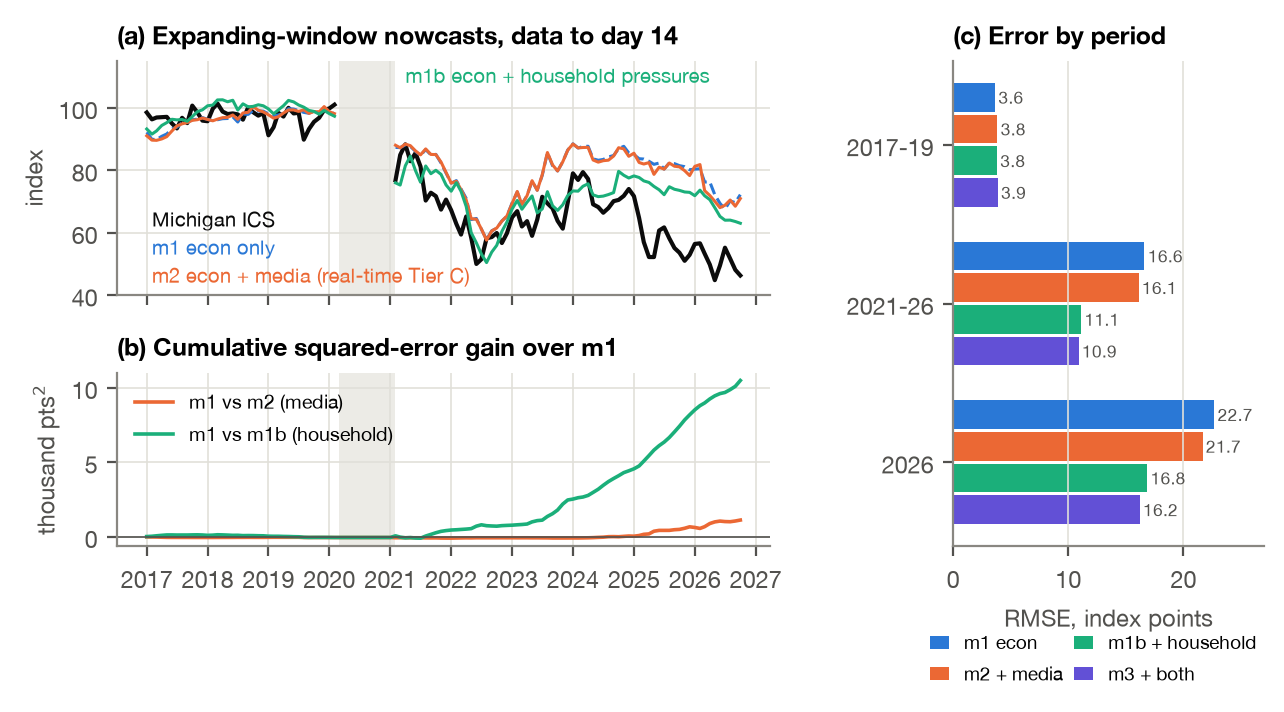

In [9]:
a = pd.read_csv(TABLES / 'rq5_accuracy.csv'); display(a.pivot_table(index=['dynamic', 'subperiod'], columns='model', values='rmse').round(2))
display(pd.read_csv(TABLES / 'rq5_clark_west.csv').round(4))
display(pd.DataFrame(R['rq5']['grid']).round(4)); print('grid hits:', R['rq5']['grid_hits_p_lt_0.10'], 'joint null:', R['rq5']['joint_null_hits'])
display(pd.DataFrame(R['rq5']['non_nested']).round(4))
print('EXPLORATORY (not pre-registered) m1 vs m1b:', json.dumps(R['rq5_exploratory_m1_vs_m1b'], indent=1))
display(Image(filename=str(FIGURES / 'fig6_prediction.png'), width=950))

**How the forecasts are made.**
- On the prediction date of month t (day 14), each model is re-estimated on all earlier months and then predicts month t from that month's real-time inputs.
- Model 1: economy only. 1b: plus household costs. 2: model 1 plus news. 3: plus both.
- The Tier C news values used at month t come from a classifier re-trained only on labels published before day 15 of t (`scripts/09b`), so nothing published after the forecast date is used.
- Every model is scored over the same months. The Clark-West test asks whether the bigger model's improvement is more than chance would give (one-sided).
- The sensitivity grid swaps the news measure and the timing; its number of hits is compared with what you get after shifting all news series in time by 13 to 57 months (a placebo).

## 10. RQ6: What evidence would contradict a media-bias explanation?

*Readings used:* External: Gambetti et al. (2023); Mian et al. (2023); Sacerdote et al. (2020). Figures 4 and 5.

**Result.** Seven falsifiers written before testing: one holds clearly (F7), two partly (F2, F3), three do not (F1, F4, F6), one cannot be settled (F5). F2 counts as partly only through the second media series; on Tier C, as coded, it does not hold. The three that fail rule out rival explanations or show a small news gain; none points to media as the main cause.

**Table 7. Falsifiers written in advance ("true" = evidence against media bias).**

| Falsifier | Rule | Result |
|---|---|---|
| F1 | News passes no test: claim rule fails and Clark-West p ≥ 0.10 for m2 vs m1 and m3 vs m1b | False: m2 vs m1 p = 0.053 |
| F2 | Sentiment moves before media (q < 0.10), media not before sentiment | Partly: false for Tier C (the coded test); true for the SF Fed index (q = 0.003 vs 0.80) |
| F3 | No negativity asymmetry in coverage | Partly: true for unemployment, false for inflation |
| F4 | Household costs close ≥ 50% of the 2026 gap in both samples | False: 6% of the 1992 to 2019 model's own gap; -8% in 2010 to 2019 (they widen it) |
| F5 | Party sentiment shifts before own-side media tone at an election | Cannot be settled: party swings of 22 to 32 index points vs outlet net negativity moving under 0.08, and 3-month windows cannot order them |
| F6 | The survey's switch to web interviews is as large as the gap | False: 6.6 points, 17% of the 39.9-point gap |
| F7 | Recalled bad price news fits the economy better than coverage | True: R² 0.80 (inflation) vs 0.61 (coverage) |

**Table 8. Three-explanation scorecard (rules written in advance).**

| Explanation | Rule result | Verdict |
|---|---|---|
| H1 pressures | Household costs close -8% of the 2026 gap in the 2010 to 2019 model and 6% of the 1992 to 2019 model's own gap; ≥ 50% needed in both | Not supported (by rule; the exploratory forecast result in Section 9 points the other way) |
| H2 perceptions | Claim rule fails; m2 vs m1 p = 0.053; media close none of the gap (Shapley: household costs -8.1%, media -1.5%, both widen it) | Partly |
| H3 measurement and model | Web interviews 17% and data revisions 3% of the gap (< 25% each); the 2010s model is unstable (fixed-model miss 29.2 > 1.25 × updating 16.6 points) | Partly (by the rule as first written, the wrong way round: not supported) |

- **Breadth.** Jan to Aug 2026 gaps are -37 to -42 points across income thirds, -38 to -45 across age groups and -33 to -41 across regions. Every party sits far below its 2017 to 2019 level: Democrats 78.8 to 38.1, independents 96.6 to 47.4, Republicans 120.2 to 89.7, even though Republicans hold the presidency and their outlets are no more negative under it.

*Against Gambetti et al. (2023):* like them, I find no unemployment negativity bias once uneven dynamics are allowed for; the asymmetry is specific to inflation.

*Why this result:* if negative coverage were the main driver, the fall should be biggest among readers of the most negative outlets, and coverage should move first. Instead every group fell by similar amounts, both parties fell, recall of bad price news follows the economy, and sentiment moves before the SF Fed index. What survives (inflation asymmetry, a small forecast gain) fits coverage amplifying a real price-level squeeze.

**In short.** The strongest evidence against media bias: the gap is broad, recall follows the economy more than coverage, and sentiment moves before the SF Fed news index. Media framing of inflation is real but explains little.

In [10]:
print(json.dumps(R['rq6'], indent=1)); print(json.dumps(R['scorecard'], indent=1)); print(json.dumps(R['shapley'], indent=1))

{
 "F1_no_media_effect_or_gain": false,
 "F2_sentiment_leads_media": false,
 "F3_no_asymmetry": {
  "U": true,
  "pi": false
 },
 "F4_h1_closes_gap": false,
 "F4_shares": [
  -0.0821678698057835,
  0.06239018963059406
 ],
 "F5_party_timing": "see rq2.party_timing",
 "F6_mode_as_large_as_gap": false,
 "F6_ratio": 0.16545548806346483,
 "F7_recall_tracks_fundamentals_better": true,
 "F7_R2": {
  "fundamentals": 0.7951450948943816,
  "media": 0.6083666526616882
 }
}
{
 "H1": {
  "verdict": "not supported",
  "share_closed_2010_19": -0.0821678698057835,
  "share_closed_long": 0.06239018963059406
 },
 "H2": {
  "verdict": "partly",
  "claim_rule": false,
  "cw_p_m1_vs_m2": 0.0533581900806378,
  "media_shapley_share": null
 },
 "H3": {
  "verdict": "partly",
  "mode_share": 0.16545548806346483,
  "revision_share": 0.02805631413390806,
  "instability_intended_rule": true,
  "instability_literal_rule": false,
  "verdict_under_literal_rule": "not supported"
 }
}
{
 "gaps": {
  "": -39.8898826339

## 11. Monitoring the pre-election period

- **Dashboard.** One self-contained page: sentiment and Model E with its band; the gap; news tone, framing, salience and accuracy (monthly Tier C and SF Fed; 2026 Opus monthly and weekly); releases and events; source mix, missing months and validation scores. An update script refreshes the economy, the gap and the Tier C and dictionary series without any AI call.
- **Groups.** Income, age and region gaps are similar (Section 10). Party is both a moderator (Democrats' ICS 38.1 vs Republicans' 89.7, Jan to Aug 2026) and a confounder, since the Republican share of respondents fell from March 2025. But an equal-weighted average of the three party indexes fell 40 points (98.5 in Feb 2017 to 2019, 58.4 in Jan to Aug 2026) against 45 for ICS over the same months, so the changing mix explains at most a few points.
- **Survey method.** Michigan's move from phone to web interviews (Apr to Jul 2024) lowers ICS by 6.6 points on its own side-by-side comparison. Adding that back gives a 2026 gap of -33.3 points, so the switch explains 17% of the gap. Michigan also finds the May 2026 low below its June 2022 web reading, so the record is not a mode effect.
- **Election timing.** From June to October the gap moved -1.0 points on average in past midterm years and -5.3 in other years; 2026's -5.0 is ordinary, so I put no 2026 change down to the campaign.
- **Cutoff and update plan.** Data end Oct 12, 2026.
  - Before election day: September CPI (Oct 14), Michigan's October final (Oct 23), Q3 GDP and September PCE (Oct 29), October jobs and the November preliminary (Nov 6).
  - After: the November final (Nov 20, first post-election interviews), the December preliminary (Dec 4), government funding expiry (Dec 11).
  - Each release reruns the update script. A midterm does not change the White House, so a 2020- or 2024-style party flip is not expected; any November move should be compared with past midterms first.

![Figure 7](outputs/figures/fig7_monitoring.png)
*Figure 7. (a) ICS (black; hollow: October preliminary) and Model E's prediction with its 95% band, Jan 2025 to Oct 2026, index points. (b) Weekly net negativity and "prices high" share of relevant 2026 headlines (Opus labels, 11 to 32 items a week; display only), with three events. (c) Change in the gap from June to October each year, index points; orange: midterm years; light grey: 2020 (COVID window, left out of the averages). Descriptive.*

{
 "mode_adjusted_gap_2026": -33.289882633983076,
 "jun_to_oct_gap_change": {
  "2010": -8.699444832008496,
  "2011": -8.79835349316916,
  "2012": 7.282472502891366,
  "2013": -11.548221884538307,
  "2014": -2.766803660222422,
  "2015": -11.645863652466659,
  "2016": -5.617982264277742,
  "2017": 2.9358401625246415,
  "2018": -1.2733902008114484,
  "2019": -2.426535858514356,
  "2020": 2.2468265165618675,
  "2021": -17.47568753517609,
  "2022": 8.547396345170402,
  "2023": -2.5250727652944107,
  "2024": 0.35771527749082566,
  "2025": -8.878203277586145,
  "2026": -4.96761678626541
 },
 "midterm_years_mean": -1.048060586967991,
 "other_years_mean": -5.303626617101458,
 "2026_jun_to_oct": -4.96761678626541,
 "party_equal_weight": {
  "mean_2017feb_2019": 98.53809523809524,
  "mean_2026_jan_aug": 58.412499999999994,
  "ics_2017feb_2019": 96.99714285714288,
  "ics_2026_jan_aug": 52.162499999999994
 },
 "party_2026": {
  "2026-01-01 00:00:00": {
   "ICS_DEM": 41.0,
   "ICS_IND": 50.8,
   "I

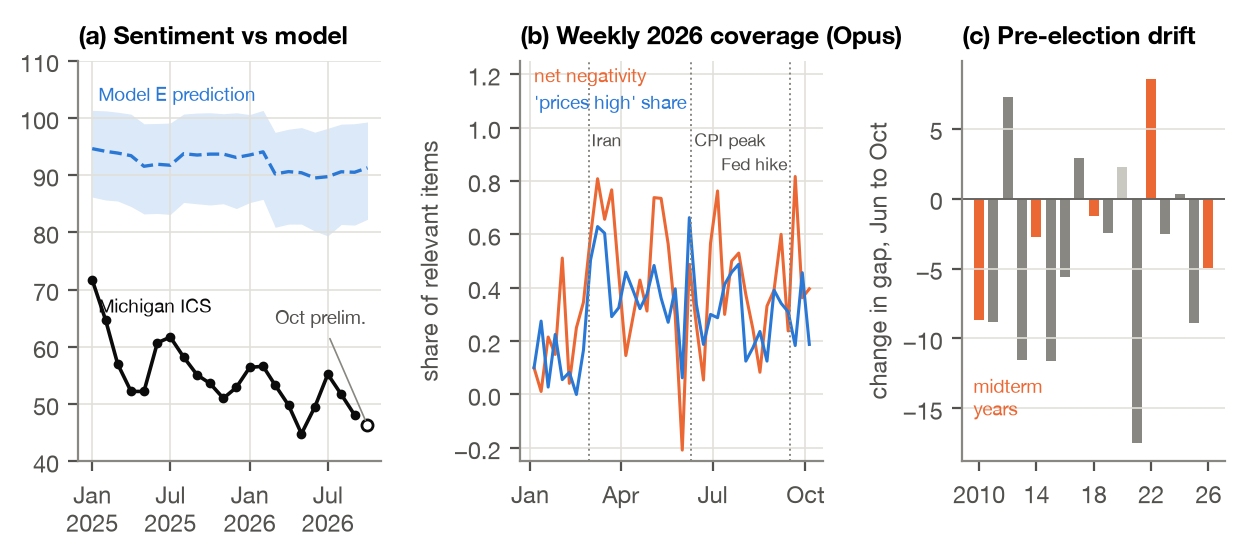

In [11]:
print(json.dumps(R['monitoring'], indent=1, default=str)[:5000])
display(Image(filename=str(FIGURES / 'fig7_monitoring.png'), width=950))

## 12. Conclusions

**What explains the drop (rough accounting of the 2026 averages, in index points; the pieces come from different checks, so the sum is approximate).**
- **The economy:** 7.1 of the 44.8-point fall since 2019 (inflation 4.0, unemployment 2.7, growth 0.4). That leaves the 39.9-point gap.
- **Measurement:** the switch from phone to web interviews, 6.6; the changing party mix of respondents, about 5 (ICS fell 45 points from 2017 to 2019 against 40 for an equal-weight average of the party indexes); data revisions, about 1.
- **Media:** news tone about 1 (at most 2.4); Reddit tone about 0 (at most 0.4).
- **Left: about 26 points, which I postulate come from three effects these data cannot isolate** (hypotheses the data fit but cannot prove): (1) the **price level**, not the inflation rate: prices sit about 14% above their 2010s trend and do not fall when inflation cools; "worse off because of higher prices" rose from 7% in 2019 to 51%, tracking the level (R² 0.81), and the biggest gaps are in personal finances and buying conditions; (2) the **cost of borrowing**: the 30-year mortgage rate went from 3.9% in 2019 to 6.2% to 7.4% in 2026, a cost CPI and PCE leave out (Bolhuis et al. 2024), and household costs cut the 2026 forecast overshoot from 22 to 16 points; (3) **partisan mood**: every party sits far below 2017 to 2019, with 22 to 32-point swings when the White House changes hands.

1. **The gap is real and large:** ICS is 39.9 points below an economy-only model in 2026 (p < 0.0005), across six data variants.
2. **The economy explains a sixth of the fall, and the price level is the strongest clue to the rest:** "worse off because of prices" follows the price level (R² 0.81) far better than the inflation rate (0.41), and household costs cut forecast misses by a third (exploratory). An association; that the pressure itself, not perception, is behind it is a hypothesis.
3. **Economic news darkens when inflation rises and does not brighten when it falls** (p = 0.002); jobs news shows no detectable tone asymmetry and most numbers are right.
4. **No detectable depressing effect of media bias.** Taken as causal, Tier C news tone accounts for about 1.0 index point of the 39.9 (at most 2.4); the claim rule fails; sentiment moves before the SF Fed index. Noisy tone pulls toward zero, but the bound is small next to 40 points.
5. **Partisanship is a large, separate factor:** party sentiment swung 22 to 32 points within two months of the 2024 election with the economy flat (one event, descriptive).
6. **For a portfolio manager:** do not read record-low Michigan sentiment as a spending signal on its own; it has not predicted real spending (E1). To forecast sentiment, put household costs in before news tone.

**Extra questions that came up (exploratory).** *Readings used:* External: Carroll, Fuhrer and Wilcox (1994); Mian et al. (2023).
- **E1. Does the gap forecast spending?** *Result:* No. Sentiment and the gap do not predict growth in real consumer spending 1 or 3 months ahead beyond the economy (p = 0.25 to 0.36), a null with modest power. *Why:* partisan and price-level pessimism need not change what households can spend (Mian et al.). *In short:* the 2026 gloom has not been a spending signal.
- **E2. Do consumers recall what the media cover?** *Result:* For prices yes (correlation 0.78), for jobs much less (layoffs 0.15, hiring 0.29). *Why:* price news echoes what people see at the till; job news does not.
- **E3. Does Reddit tone move sentiment, the way RQ2 asks of news?** *How:* Tier C scored all 50,926 Reddit posts (15,265 relevant, a median of 32 a month); monthly net negativity with subreddit fixed effects (r/personalfinance is missing in 69 of 202 months, so a plain average would move with the mix); then the RQ2 tests.
  - *Result:* No detectable link. With the economy only, -3.3 index points per 1.0 of Reddit net negativity (p = 0.18); with household costs the sign flips (+2.1, p = 0.72); month-to-month changes p = 0.42; neither series moves first (p = 0.89 and 0.71).
  - *Size:* Reddit net negativity rose 0.08 from 2019 to 2026, so even taken as causal it explains +0.2 index points of the gap with household costs (90% CI -0.4 to +0.7), against -1.0 (-2.4 to +0.4) for news; with the economy only, -0.3 (-0.8 to +0.2).
  - *Caveat:* Tier C finds relevant Reddit posts well (macro-F1 0.87 on the 150 Reddit gold items) but reads their tone poorly (0.47 on the 59 relevant ones, where Opus scores 0.92), and the monthly series is noisy (split-half reliability 0.41); both pull toward zero. Reddit tone barely tracks news tone (correlation 0.13).
  - *In short:* no sign that Reddit gloom drives the gap, with a weak measure of it.

In [12]:
print(json.dumps(R['extras'], indent=1))
# E3 (exploratory): Reddit tone scored by Tier C, through the RQ2 tests
print(json.dumps({k: RD[k] for k in ['reddit_gold', 'corpus', 'reddit_change_2019_2026', 'changes', 'toda_yamamoto']}, indent=1))
display(pd.read_csv(TABLES / 'e3_reddit_level_models.csv').round(3))

{
 "E1_h1_ICS": {
  "N": 188,
  "coef": -0.006323731857286108,
  "p": 0.3612150110506036,
  "sample": [
   "2010-01-01",
   "2026-07-01"
  ]
 },
 "E1_h1_gap": {
  "N": 68,
  "coef": -0.036480581840579535,
  "p": 0.268458031616877,
  "sample": [
   "2020-01-01",
   "2026-07-01"
  ]
 },
 "E1_h3_ICS": {
  "N": 186,
  "coef": -0.007842955402728568,
  "p": 0.300239123727843,
  "sample": [
   "2010-01-01",
   "2026-05-01"
  ]
 },
 "E1_h3_gap": {
  "N": 66,
  "coef": -0.05020895703219237,
  "p": 0.2539400076779659,
  "sample": [
   "2020-01-01",
   "2026-05-01"
  ]
 },
 "E2_recall_vs_coverage": [
  {
   "media": "tc_prices_high",
   "recall": "unfav_high_prices",
   "N": 189,
   "r_levels": 0.7799786232081544,
   "r_changes": 0.3891844553142989
  },
  {
   "media": "tc_layoffs",
   "recall": "unfav_unemp",
   "N": 189,
   "r_levels": 0.14755611076864408,
   "r_changes": 0.10255602455240762
  },
  {
   "media": "tc_hiring",
   "recall": "fav_emp",
   "N": 189,
   "r_levels": 0.2888317206911024

,model,N,nu,coef,se,p_expected_sign,implied_contribution_if_causal,robustness_value,ci_lo,ci_hi,loyo_max_p,loyo_coef_range,drop_2021_22
0,economy + Reddit,191,13,-3.315,3.466,0.178,-0.275,0.054,-0.784,0.234,NaN,NaN,NaN
1,economy + household costs + Reddit,191,13,2.129,3.631,0.716,0.177,0.050,-0.357,0.710,0.976,"[-0.09644566798657195, 3.7488242118126927]","{'coef': 4.408457962591509, 'p_two_sided': 0.25219046762112596}"
2,economy + household costs + news + Reddit,191,13,2.117,3.460,0.724,0.176,0.050,-0.333,0.684,NaN,NaN,NaN


## 13. Limitations and ethics

- **Gold labels made by models, with my corrections.** The two passes are models' labels plus my corrections (12 and 15 items) and a third model settling disagreements. One person corrected both, so they are not independent; two independent people could agree less. On items where the passes disagreed on tone, Opus tone F1 is 0.46. Two independent people labelling with the guide is the first thing to do with more time.
- **AI hindsight.** Opus knows what happened after 2010 to 2025 and may label old headlines with hindsight (Glasserman and Lin 2023). Items were shown without dates, and the dictionary and SF Fed series cannot have hindsight; results agree in sign, but this cannot be ruled out.
- **Headlines only, sampled.** Google's 100-item cap makes each window a ranked sample; no article text; Reddit is a narrow, self-selected audience; exposure is not observed.
- **Thin history labelling.** The usage limit and a 38% relevance rate made the Opus history series quarterly; monthly tests use Tier C, which is noisier (tone F1 0.61 on all gold items, 0.47 on relevant Reddit items) and pulls toward zero. In-sample tests use one Tier C trained on all labels; only forecasts use the real-time version.
- **Framing scores only from Opus's sample.** Emotional wording, framing, attribution and number accuracy exist quarterly for 2010 to 2025 and monthly for 2026 only (Section 3), so they cannot enter the monthly models and are read descriptively.
- **Model scope.** Model E is linear and trained on a decade without price-level shocks; I did not build Bolhuis et al.'s cost-of-money index. Six household costs is a manageable set, not a complete one. Party is handled descriptively, not by reweighting respondents.
- **Ethics.** Public or licensed data only. No human-subject research was run (the experiment is a proposal and needs IRB approval first). Reddit usernames were scrambled at download. No headline or post text is redistributed: the repo has labels and ids, and evidence quotes stay local. One privacy slip: a verification subagent put my NYU email in one request header to bls.gov; it is disclosed in the AI-use statement.

## 14. References

<p class="refs"><b>Class readings.</b> Sacerdote, B., Sehgal, R., Cook, M. (2020). Why Is All COVID-19 News Bad News? NBER WP 28110. · Bybee, L., Kelly, B., Manela, A., Xiu, D. (2024). Business News and Business Cycles. J. Finance 79(5): 3105-3147. · Loughran, T., McDonald, B. (2011). When Is a Liability Not a Liability? J. Finance 66(1): 35-65. · Psomakelis, E. et al. (2014). Comparing Methods for Twitter Sentiment Analysis. KDIR. · Carvalho, J., Plastino, A. (2020). On the Evaluation and Combination of State-of-the-Art Features in Twitter Sentiment Analysis. Artificial Intelligence Review. · Souza, T. et al. (2015). Twitter Sentiment Analysis Applied to Finance: A Case Study in the Retail Industry. · Jurafsky, D., lecture slides on sentiment, citing O'Connor, B., Balasubramanyan, R., Routledge, B., Smith, N. (2010). From Tweets to Polls. ICWSM 4(1): 122-129.<br>
<b>External.</b> Bolhuis, M., Cramer, J., Schulz, K., Summers, L. (2024). The Cost of Money is Part of the Cost of Living. NBER WP 32163. · Shapiro, A., Sudhof, M., Wilson, D. (2022). Measuring News Sentiment. J. Econometrics 228(2): 221-243. · Buckman, S., Shapiro, A., Sudhof, M., Wilson, D. (2020). News Sentiment in the Time of COVID-19. FRBSF Economic Letter 2020-08. · Doms, M., Morin, N. (2004). Consumer Sentiment, the Economy, and the News Media. FRBSF WP 2004-09. · Soroka, S. (2006). Good News and Bad News. J. Politics 68(2): 372-385. · Gambetti, L., Maffei-Faccioli, N., Zoi, S. (2023). Bad News, Good News: Coverage and Response Asymmetries. FEDS 2023-001. · Harris, B., Sojourner, A. (2024). Why are Americans so displeased with the economy? Brookings, Jan 5. · Gentzkow, M., Shapiro, J. (2010). What Drives Media Slant? Econometrica 78(1): 35-71. · Stantcheva, S. (2024). Why Do We Dislike Inflation? BPEA Spring: 1-46. · D'Acunto, F., Malmendier, U., Ospina, J., Weber, M. (2021). Exposure to Grocery Prices and Inflation Expectations. JPE 129(5): 1615-1639. · Malmendier, U., Nagel, S. (2016). Learning from Inflation Experiences. QJE 131(1): 53-87. · Mian, A., Sufi, A., Khoshkhou, N. (2023). Partisan Bias, Economic Expectations, and Household Spending. REStat 105(3): 493-510. · Carroll, C. (2003). Macroeconomic Expectations of Households and Professional Forecasters. QJE 118(1): 269-298. · Carroll, C., Fuhrer, J., Wilcox, D. (1994). Does Consumer Sentiment Forecast Household Spending? AER 84(5): 1397-1408. · Baker, S., Bloom, N., Davis, S. (2016). Measuring Economic Policy Uncertainty. QJE 131(4): 1593-1636. · Lazarus, E., Lewis, D., Stock, J., Watson, M. (2018). HAR Inference: Recommendations for Practice. JBES 36(4): 541-559. · Newey, W., West, K. (1987). Econometrica 55(3): 703-708. · Künsch, H. (1989). Ann. Statist. 17(3): 1217-1241. · Clark, T., West, K. (2007). J. Econometrics 138(1): 291-311. · Diebold, F., Mariano, R. (1995). JBES 13(3): 253-263. · Harvey, D., Leybourne, S., Newbold, P. (1997). IJF 13(2): 281-291. · Toda, H., Yamamoto, T. (1995). J. Econometrics 66(1-2): 225-250. · Granger, C. (1969). Econometrica 37(3): 424-438. · Benjamini, Y., Hochberg, Y. (1995). JRSS-B 57(1): 289-300. · Cohen, J. (1960). Educ. Psychol. Meas. 20(1): 37-46. · Landis, J., Koch, G. (1977). Biometrics 33(1): 159-174. · Krippendorff, K. (2004). Content Analysis, 2nd ed. · Gwet, K. (2008). Br. J. Math. Stat. Psychol. 61(1): 29-48. · Cinelli, C., Hazlett, C. (2020). JRSS-B 82(1): 39-67. · Hulley, S. et al. (2013). Designing Clinical Research, 4th ed. · Glasserman, P., Lin, C. (2023). Assessing Look-Ahead Bias in Stock Return Predictions Generated by GPT Sentiment Analysis. arXiv:2309.17322.<br>
<b>Data and facts.</b> University of Michigan Surveys of Consumers (sca.isr.umich.edu; data.sca.isr.umich.edu tables; technical documentation of the web transition, docid 75437, Apr 5, 2024; "Sentiment, Web-Based Data Collection, and Partisanship", Jul 10, 2026; "Gasoline Prices and Expected Consumer Spending", Oct 9, 2026, for the Iran conflict date). · BLS (LNS14000000; Employment Situation and CPI releases; 2025 lapse release dates). · BEA (PCE, GDP; release schedule). · ALFRED and FRED, Federal Reserve Bank of St. Louis (18 series; ids listed in the repo). · SF Fed Daily News Sentiment Index. · Economic Policy Uncertainty, news-based index (policyuncertainty.com). · Atlanta Fed GDPNow. · Google News RSS. · Arctic Shift Reddit archive. · AllSides media bias ratings. · Pew Research Center (2025), The Political Gap in Americans' News Sources, Jun 10. · Events: Federal Reserve press releases (Jan 28, May 22, Sep 16, 2026); Supreme Court, Learning Resources v. Trump (Feb 20, 2026); Federal Register (Proclamation 11012; Section 301 actions, Jul 2026); EIA weekly retail gasoline; BLS Employment Situation (Mar 6, Oct 2, 2026) and CPI (Jun 10, 2026); CRS R41759 (shutdowns); White House (H.R. 6500, Sep 2, 2026). · Course data file (Perceptual Bias Data). · AI: Claude Opus 5.5, Sonnet 5.5, Haiku 5.5 and Fable 5.1 via Claude Code, Anthropic.</p>